# Reachy 1.2 (R0027) ROS 2 log analysis

**Purpose.** Understand how healthy the robot's software/hardware stack has been across all launch sessions (2026-08-20 .. 2026-11-12) and what that means for the zero-shot AI tabletop-assistant project, which depends on (a) the two head cameras, (b) the Orbita neck (head pose for camera-to-robot grounding) and later (c) the right arm / gripper.

**Robot.** R0027, Reachy 1.2 `starter_kit_right`: right arm + Orbita neck head with two zoom cameras, no mobile base.

**Data source.** CSV tables written by `etl/reachy_log_etl.py` from the raw ROS 2 logs (`data/csv/`). Nothing here reads raw logs.

| Table | Grain |
|---|---|
| `sessions` | one launch session (73): type, milestones, readiness, clock steps |
| `processes` | one launched process (1278): exit code, uptime |
| `events` | one parsed log line (88,147, spam excluded) - **contains launch AND node duplicates** |
| `hw_errors` | one throttled ros2_control bus-error window (67,236) |
| `fan_events`, `fan_intervals` | fan ON/OFF events and ON intervals (thermal proxy) |
| `controller_lifecycle` | load / configure / activate times per controller |
| `spam_summary` | aggregated `service SetSpeed not available` spam per file |
| `file_inventory` | every raw log file (1426), incl. empty `NODATA` |
| `message_templates` | normalised message templates with counts |
| `daily_summary` | per UTC day roll-up |

**Caveats that apply throughout**
1. `hw_errors` rows are **throttled (30 s windows)**: one row = "at least one such error in that window", not one bus error. Use them as a lower bound / rate proxy. They are logged at INFO by ros2_control.
2. `events` holds the same message from two sources (`source_kind` = `launch` / `node`). Never count both; this notebook uses the canonical source per table (launch for most, `ros2_control_node` node files for hw errors).
3. The robot wall-clock is stepped backwards (NTP) in a few sessions, so some times and durations are slightly off there (section 8).
4. `mobile_base` sessions always fail (no `/dev/vesc_wheels`) and emit the `SetSpeed` spam; the robot has no mobile base, so they are noise for this project.
5. The logs carry **no per-frame camera timing**, so camera health can only be inferred from start-up milestones and process deaths.
6. Dates are UTC unless a column says `local` (America/Los_Angeles, a convenience view; the robot itself runs on UTC+2).
7. **`duration_s` / "uptime" is a logged span** (first to last log line), not a run time: a healthy, quiet stack logs nothing after bringup. Section 12 gives lower and upper bounds per session and separates all-bus outages from ordinary error windows; read sections 2, 5, 6 and 10 with that in mind.


## 0. Setup and data locator

**What it does.** Imports pandas / numpy / matplotlib only, sets display options and finds the CSV folder in this order: the `DATA_DIR` form field (Colab + Google Drive), `../data/csv` (local run from `notebooks/`), `data/csv`, and finally (Colab only) an upload prompt for `reachy_logs_csv.zip`.

**How to read the output.** It prints which folder was chosen. If you are on Colab and the files live on Drive, edit `DATA_DIR` in the form, e.g. `/content/drive/MyDrive/reachy_logs_csv`.

**Caveat.** The Colab-only imports are guarded, so the same cell runs unchanged locally.

In [1]:
# @title Setup: imports, display options and data locator
import os, io, zipfile
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LogNorm
from matplotlib.patches import Patch

try:
    from google.colab import drive, files   # only exists on Colab
    IN_COLAB = True
except Exception:
    IN_COLAB = False

DATA_DIR = "/content/drive/MyDrive/reachy_logs_csv"  # @param {type:"string"}
TZ = "America/Los_Angeles"  # local-time convenience view

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.max_rows", 80)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "axes.titlesize": 12})

def _has_csvs(p):
    return p is not None and (Path(p) / "sessions.csv").exists()

def locate_data():
    cands = [DATA_DIR, "../data/csv", "data/csv", "/content/reachy_logs_csv", "/content/csv"]
    if IN_COLAB and str(DATA_DIR).startswith("/content/drive") and not Path("/content/drive/MyDrive").exists():
        try:
            drive.mount("/content/drive")
        except Exception as e:
            print("Drive mount failed:", e)
    for c in cands:
        if c and _has_csvs(c):
            return Path(c)
    if IN_COLAB:
        print("CSV folder not found - upload reachy_logs_csv.zip")
        up = files.upload()
        name = next(iter(up))
        out = Path("/content/reachy_logs_csv"); out.mkdir(exist_ok=True)
        with zipfile.ZipFile(io.BytesIO(up[name])) as z:
            z.extractall(out)
        for sub in [out] + [d for d in out.rglob("*") if d.is_dir()]:
            if _has_csvs(sub):
                return sub
    raise FileNotFoundError("sessions.csv not found. Set DATA_DIR, run from notebooks/, or upload reachy_logs_csv.zip on Colab.")

DATA_PATH = locate_data()
print("Using data folder:", DATA_PATH.resolve())
print("pandas", pd.__version__, "| matplotlib", matplotlib.__version__, "| Colab:", IN_COLAB)

Using data folder: /sessions/rcw-01lugcdogchvoedtuwnrk1ug/mnt/Reachy-Lab/reachy-1-2-ros/data/csv
pandas 2.3.3 | matplotlib 3.10.9 | Colab: False


## 0b. Loader

**What it does.** `load_csvs()` reads the 11 CSVs into a dict of DataFrames, parses every `*_utc` / `ts_utc` column to timezone-aware UTC datetimes, coerces boolean columns to real `bool`, and prints a shape summary.

**How to read the output.** The row counts should match the ETL manifest (73 sessions, 1278 processes, 88,147 events, 67,236 hw error windows ...). The `UTC range` column is a quick sanity check that the data cover 2026-08-20 to 2026-11-12.

**Caveat.** `events` is the largest table (~25 MB, still loads in a few seconds). Timestamps are as logged by the robot (UTC), with the clock-step caveat of section 8.

In [2]:
# @title Loader: load_csvs() with parsed UTC datetimes and bool dtypes
import json
TABLES = ["sessions", "processes", "events", "hw_errors", "fan_events", "fan_intervals",
          "controller_lifecycle", "spam_summary", "file_inventory", "message_templates", "daily_summary"]
BOOL_COLS = {"sessions": ["sdk_ready", "cameras_ready", "kinematics_ready"],
             "processes": ["died", "finished_cleanly"], "fan_intervals": ["closed"],
             "file_inventory": ["is_empty"], "events": ["is_continuation"]}

def _to_bool(s):
    return s.astype(str).map({"True": True, "False": False}).fillna(False).astype(bool)

def load_csvs(data_dir=DATA_PATH):
    data_dir = Path(data_dir)
    out = {}
    for name in TABLES:
        df = pd.read_csv(data_dir / f"{name}.csv", low_memory=False)
        for c in df.columns:
            if c.endswith("_utc") or c == "ts_utc":
                df[c] = pd.to_datetime(df[c], utc=True, errors="coerce")
        for c in BOOL_COLS.get(name, []):
            if c in df.columns:
                df[c] = _to_bool(df[c])
        out[name] = df
    mf = data_dir / "etl_run_manifest.json"
    out["manifest"] = json.loads(mf.read_text()) if mf.exists() else {}
    # local-time convenience columns
    s = out["sessions"]
    s["date"] = pd.to_datetime(s["date"])
    s["start_local"] = s["start_utc"].dt.tz_convert(TZ)
    out["events"]["ts_local"] = out["events"]["ts_utc"].dt.tz_convert(TZ)
    summ = []
    for n in TABLES:
        d = out[n]
        tcols = [c for c in d.columns if c.endswith("_utc") or c == "ts_utc"]
        rng = ""
        if tcols:
            c = tcols[0]
            rng = f"{d[c].min():%Y-%m-%d} .. {d[c].max():%Y-%m-%d}"
        summ.append({"table": n, "rows": len(d), "cols": d.shape[1], "UTC range": rng})
    print(pd.DataFrame(summ).to_string(index=False))
    return out

T = load_csvs()
S, P, EV, HW = T["sessions"], T["processes"], T["events"], T["hw_errors"]
FE, FI, CL, SP = T["fan_events"], T["fan_intervals"], T["controller_lifecycle"], T["spam_summary"]
FILES, MT, DAILY, MANIFEST = T["file_inventory"], T["message_templates"], T["daily_summary"], T["manifest"]
print("\nbool dtypes:", S[["sdk_ready", "cameras_ready", "kinematics_ready"]].dtypes.unique(), "| UTC dtype:", S["start_utc"].dtype)

               table  rows  cols                UTC range
            sessions    73    35 2026-08-20 .. 2026-11-12
           processes  1278    14 2026-08-20 .. 2026-11-12
              events 88147    13 2026-08-20 .. 2026-11-12
           hw_errors 67236     9 2026-08-20 .. 2026-10-27
          fan_events  2157     7 2026-08-20 .. 2026-10-27
       fan_intervals  1082     8 2026-08-20 .. 2026-10-27
controller_lifecycle   586     9 2026-08-20 .. 2026-11-12
        spam_summary    25    11 2026-08-20 .. 2026-11-12
      file_inventory  1426    17 2026-08-20 .. 2026-11-12
   message_templates   310    13 2026-08-20 .. 2026-10-27
       daily_summary    17    11                         

bool dtypes: [dtype('bool')] | UTC dtype: datetime64[ns, UTC]


## 0c. Derived per-session table

**What it does.** Builds the working table `R` = one row per **robot_bringup** session (the 59 sessions that actually ran the robot) with uptime, month, ros2_control_node death flag, camera-process death flag and the number of hardware error windows per system (Arm / Head / Neck) and per uptime hour. All later robot-health sections reuse `R`.

**How to read the output.** The printed counts are the basis for the later sections: how many robot sessions there are, total uptime and how many sessions have any error windows. The assertion confirms that our per-session window counts equal the ETL's own `n_hw_error_rows`.

**Caveat.** `uptime_h` = the launch.log span (step-corrected by the ETL), not individual process uptime. `hw_errors` rows are throttled windows (see overview).

In [3]:
# @title Derived tables: robot sessions R with uptime, deaths and error-window counts
S["month"] = S["date"].dt.strftime("%Y-%m")
S["uptime_h"] = S["duration_s"] / 3600.0
R = S[S["launch_type"] == "robot_bringup"].copy()

died = P[P["died"]]
cn_death = died[died["executable"] == "ros2_control_node"]
cam_death = died[died["executable"].str.contains("camera", case=False, na=False)]
R["cn_death"] = R["session_id"].isin(cn_death["session_id"])
R["cam_death"] = R["session_id"].isin(cam_death["session_id"])

wcnt = (HW.groupby(["session_id", "system"]).size().unstack(fill_value=0)
          .reindex(columns=["ArmSystem", "HeadSystem", "NeckSystem"], fill_value=0))
wcnt.columns = ["arm_w", "head_w", "neck_w"]
R = R.join(wcnt, on="session_id")
for c in ["arm_w", "head_w", "neck_w"]:
    R[c] = R[c].fillna(0).astype(int)
R["total_w"] = R[["arm_w", "head_w", "neck_w"]].sum(axis=1)
assert (R["total_w"] == R["n_hw_error_rows"]).all(), "window counts differ from ETL n_hw_error_rows"
R["w_per_h"] = R["total_w"] / R["uptime_h"]
R["neck_w_per_h"] = R["neck_w"] / R["uptime_h"]
R["last_w_epoch"] = R["session_id"].map(HW.groupby("session_id")["epoch"].max())
R["first_neck_s"] = R["session_id"].map(HW[HW["system"] == "NeckSystem"].groupby("session_id")["s_since_session_start"].min())
R["short_session"] = R["duration_s"] < 60
HW["date"] = HW["ts_utc"].dt.tz_localize(None).dt.normalize()

print(f"robot_bringup sessions: {len(R)} | total uptime: {R['uptime_h'].sum():.2f} h | "
      f"sessions < 60 s: {int(R['short_session'].sum())}")
print(f"sessions with any hw error window: {(R['total_w'] > 0).sum()} | ros2_control_node died: {int(R['cn_death'].sum())} | camera process died: {int(R['cam_death'].sum())}")
print("\nUptime by month (robot sessions):")
print(R.groupby("month").agg(sessions=("session_id", "size"), uptime_h=("uptime_h", "sum"),
                             sessions_lt60s=("short_session", "sum"), hw_windows=("total_w", "sum")).round(2))

robot_bringup sessions: 59 | total uptime: 95.17 h | sessions < 60 s: 36
sessions with any hw error window: 45 | ros2_control_node died: 18 | camera process died: 2

Uptime by month (robot sessions):
         sessions  uptime_h  sessions_lt60s  hw_windows
month                                                  
2026-08        22      9.91              19        4419
2026-09         8      6.02               5        1204
2026-10        28     79.24              11       61613
2026-11         1      0.00               1           0


## 1. Data inventory and quality

**What it does.** Summarises the 1426 raw log files by bucket (`sessions` = launch.log, `nodes` = per-node rcutils logs, `NODATA` = empty placeholder files), bytes by file family, empty-file share, malformed lines, and how much of the log volume is `SetSpeed` spam.

**How to read the output.** Table 1 = bucket sizes; table 2 = bytes per family; the bar charts show (left) lines spam vs useful, (middle) bytes spam vs other, (right) empty vs non-empty files. Spam share is given both ways: over *all* lines read (launch + node duplicates) and over launch.log lines only (the number the context quotes, ~2.5 M).

**Caveat.** The spam is logged in both launch.log and the node file, so the all-lines figure (5.03 M) is about twice the launch-only figure (2.5 M). `bytes_est` for spam is a character count, so spam bytes are approximate.

In [4]:
# @title 1a. File buckets, bytes by family, empty files, malformed lines
bk = FILES.groupby("bucket").agg(files=("relpath", "size"), MB=("size_bytes", lambda x: x.sum() / 1e6),
                                 empty_files=("is_empty", "sum"), lines=("n_lines", "sum"),
                                 malformed=("n_malformed", "sum")).round(2)
bk["empty_share_%"] = (100 * bk["empty_files"] / bk["files"]).round(1)
print("Table 1 - files by bucket"); print(bk, "\n")

fam = FILES.groupby("family").agg(files=("relpath", "size"), MB=("size_bytes", lambda x: x.sum() / 1e6),
                                  empty=("is_empty", "sum")).sort_values("MB", ascending=False).round(2)
fam["MB_share_%"] = (100 * fam["MB"] / fam["MB"].sum()).round(2)
print("Table 2 - bytes by family"); print(fam, "\n")

tot_files = len(FILES); n_empty = int(FILES["is_empty"].sum())
print(f"Empty files: {n_empty}/{tot_files} = {100*n_empty/tot_files:.1f}%  (NODATA bucket: {int((FILES.bucket=='NODATA').sum())})")
print(f"Malformed lines (file_inventory): {int(FILES['n_malformed'].sum())} | manifest says {MANIFEST.get('malformed_lines')}")
print(f"Unmatched files (no session): {int(FILES['session_id'].isna().sum())}  -> families:", FILES[FILES['session_id'].isna()]['family'].value_counts().to_dict())

Table 1 - files by bucket
          files      MB  empty_files    lines  malformed  empty_share_%
bucket                                                                 
NODATA      660    0.00          660        0          0          100.0
nodes       693  260.01            0  2591714         52            0.0
sessions     73  371.09            0  2526752          0            0.0 

Table 2 - bytes by family
                        files      MB  empty  MB_share_%
family                                                  
launch                     73  371.09      0       58.80
python3                   632  254.19    596       40.28
ros2_control_node          59    5.67      0        0.90
python3.10                590    0.15      5        0.02
rplidar_scan_publisher     13    0.00      0        0.00
robot_state_publisher      59    0.00     59        0.00 

Empty files: 660/1426 = 46.3%  (NODATA bucket: 660)
Malformed lines (file_inventory): 52 | manifest says 52
Unmatched files (no 

### 1b. Spam vs useful lines/bytes and empty vs non-empty files (bar charts)

Spam vs useful lines and bytes, and empty vs non-empty files. **What it does:** computes the spam share three ways (all lines, launch.log lines only, bytes) and draws three bar charts. **How to read it:** left = lines, middle = bytes, right = files per bucket. **Caveat:** spam is double counted across launch/node files; spam bytes are a character-count estimate.

Spam share of ALL lines read (launch+node): 5,030,000/5,118,466 = 98.27%
Spam share of launch.log lines only:        2,515,100/2,526,752 = 99.54%
Spam share of bytes (approx, char count):   623.7 MB / 631.1 MB = 98.8%
spam by source_kind:
              files    lines     MB
source_kind                       
launch          13  2515100  369.7
node            12  2514900  254.0


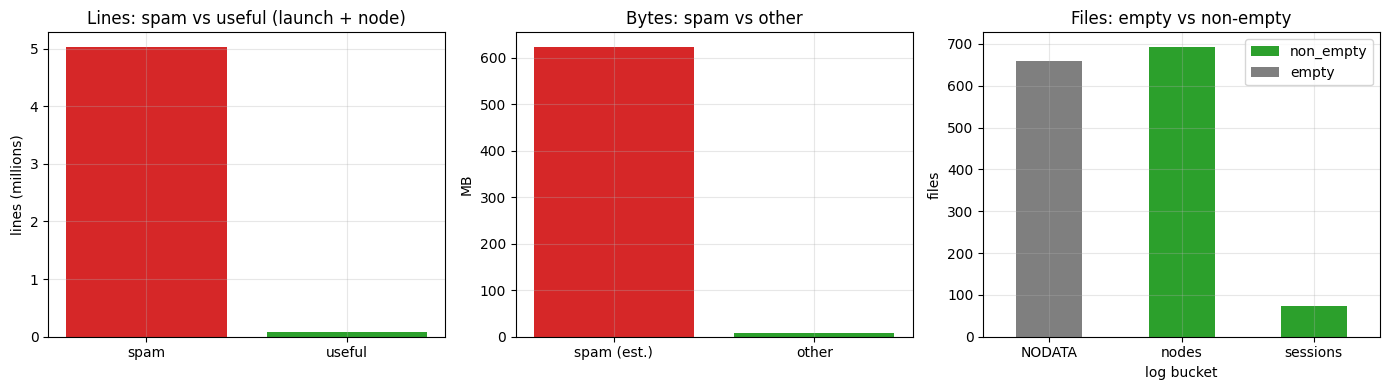

In [5]:
# @title 1b. Spam vs useful lines/bytes and empty vs non-empty files (bar charts)
total_lines = MANIFEST["lines_read"]; spam_lines = MANIFEST["spam_lines"]
launch_lines = int(S["n_lines"].sum()); launch_spam = int(S["n_spam_lines"].sum())
total_bytes = int(FILES["size_bytes"].sum()); spam_bytes = int(SP["bytes_est"].sum())
print(f"Spam share of ALL lines read (launch+node): {spam_lines:,}/{total_lines:,} = {100*spam_lines/total_lines:.2f}%")
print(f"Spam share of launch.log lines only:        {launch_spam:,}/{launch_lines:,} = {100*launch_spam/launch_lines:.2f}%")
print(f"Spam share of bytes (approx, char count):   {spam_bytes/1e6:.1f} MB / {total_bytes/1e6:.1f} MB = {100*spam_bytes/total_bytes:.1f}%")
print("spam by source_kind:\n", SP.groupby("source_kind").agg(files=("source_file", "size"), lines=("n_spam_lines", "sum"), MB=("bytes_est", lambda x: x.sum()/1e6)).round(1))

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].bar(["spam", "useful"], [spam_lines / 1e6, (total_lines - spam_lines) / 1e6], color=["tab:red", "tab:green"])
ax[0].set_ylabel("lines (millions)"); ax[0].set_title("Lines: spam vs useful (launch + node)")
ax[1].bar(["spam (est.)", "other"], [spam_bytes / 1e6, (total_bytes - spam_bytes) / 1e6], color=["tab:red", "tab:green"])
ax[1].set_ylabel("MB"); ax[1].set_title("Bytes: spam vs other")
ne = FILES.groupby("bucket")["is_empty"].agg(empty="sum", total="size"); ne["non_empty"] = ne["total"] - ne["empty"]
ne[["non_empty", "empty"]].plot.bar(stacked=True, ax=ax[2], color=["tab:green", "tab:gray"], rot=0)
ax[2].set_ylabel("files"); ax[2].set_xlabel("log bucket"); ax[2].set_title("Files: empty vs non-empty")
for a in ax[:2]: a.set_xlabel("")
plt.tight_layout(); plt.show()

## 2. Session timeline

**What it does.** A Gantt-style chart (one bar per launch session, chronological) coloured by `launch_type`, then sessions per day and robot uptime hours per day.

**How to read the output.** In the Gantt the bar's left edge is the session start (UTC) and its length is the duration; bars shorter than ~3 hours are drawn with a minimum visible width, so very short sessions (~20 s) appear as thin ticks of equal size. Orange `mobile_base` bars are the failing wheel-base launches that run in parallel with a robot bringup. The daily charts show how often the robot was powered up and for how long.

**Caveat.** Sessions are attributed to the UTC date of their start. Start times can be off by up to the clock-step amount in the 4 sessions of section 8.

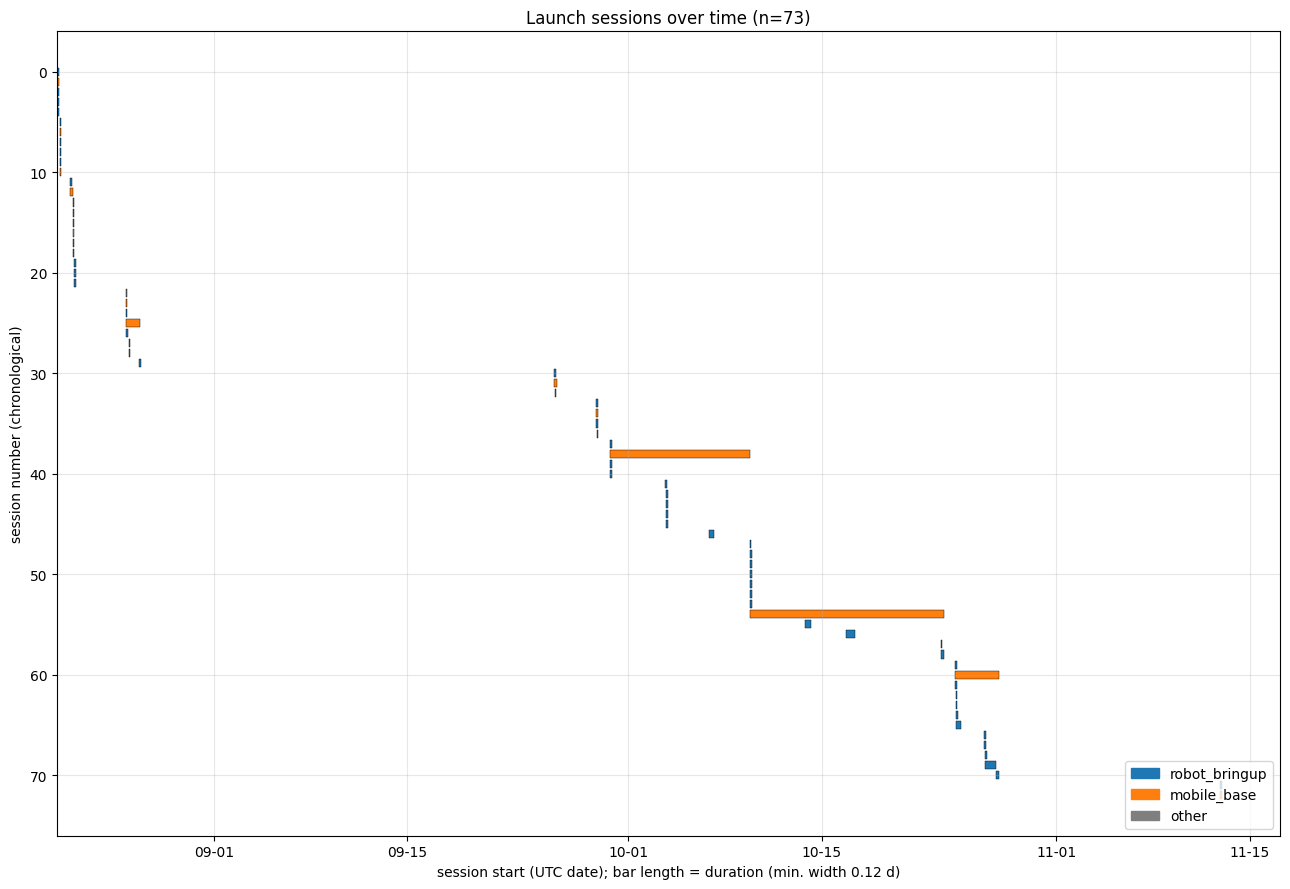

               sessions  total_h  median_s
launch_type                               
mobile_base          13   700.29  13328.79
other                 1     0.00      0.46
robot_bringup        59    95.17     21.73


In [6]:
# @title 2a. Gantt chart of all launch sessions coloured by launch_type
COLORS = {"robot_bringup": "tab:blue", "mobile_base": "tab:orange", "other": "tab:gray"}
Ss = S.sort_values("start_utc").reset_index(drop=True)
left = mdates.date2num(Ss["start_utc"].dt.tz_localize(None))
width = np.maximum(Ss["duration_s"] / 86400.0, 0.12)   # min visible width 0.12 d (~3 h)
fig, ax = plt.subplots(figsize=(13, 9))
ax.barh(Ss.index, width, left=left, color=Ss["launch_type"].map(COLORS), edgecolor="k", linewidth=0.3)
ax.xaxis_date(); ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d")); ax.invert_yaxis()
ax.set_xlabel("session start (UTC date); bar length = duration (min. width 0.12 d)")
ax.set_ylabel("session number (chronological)"); ax.set_title("Launch sessions over time (n=%d)" % len(Ss))
ax.legend(handles=[Patch(color=c, label=k) for k, c in COLORS.items()], loc="lower right")
plt.tight_layout(); plt.show()
print(Ss.groupby("launch_type").agg(sessions=("session_id", "size"), total_h=("uptime_h", "sum"), median_s=("duration_s", "median")).round(2))

### 2b. Sessions per day and robot uptime hours per day

Sessions per day and robot uptime per day. **What it does:** stacked bars of sessions per UTC day by launch type, and robot uptime hours per day, plus monthly totals and the longest sessions. **How to read it:** the lower panel is the real robot-running time. **Caveat:** uptime is the launch.log span (step-corrected); days are UTC.

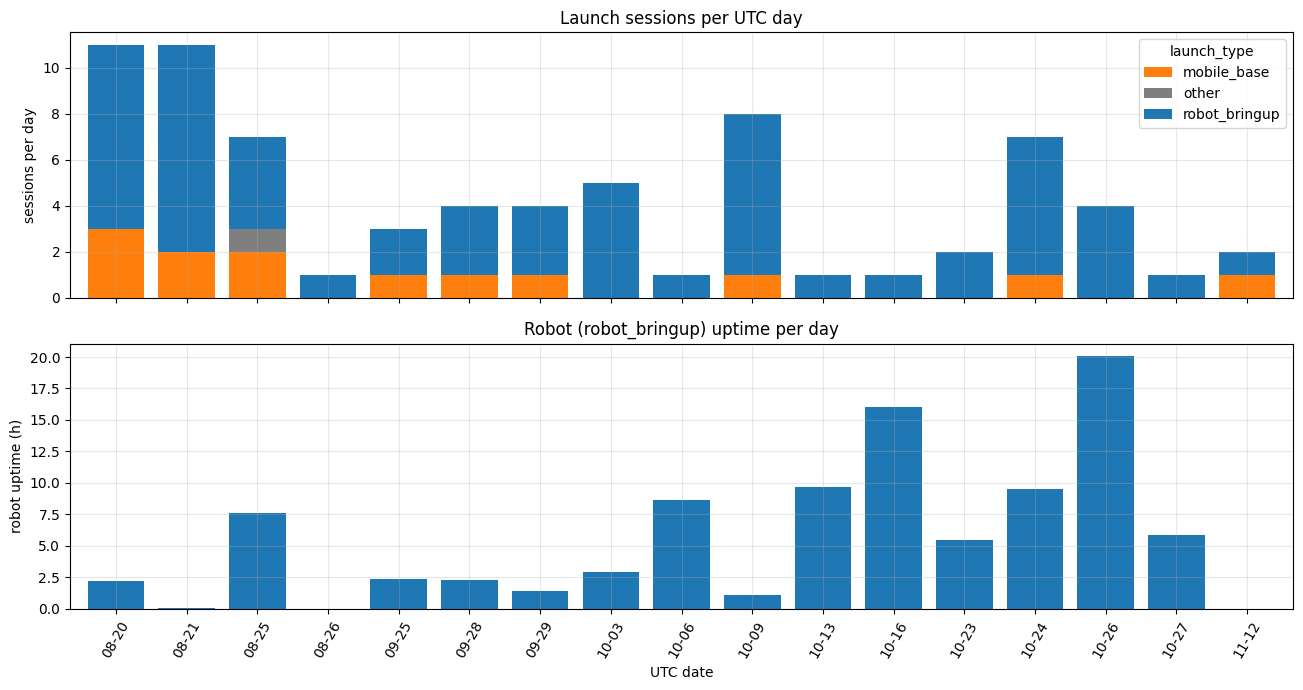

Robot active days: 17 | total uptime 95.17 h | longest day 2026-10-26 = 20.07 h
month
2026-08     9.91
2026-09     6.02
2026-10    79.24
2026-11     0.00

Top 5 longest robot sessions:
                                          session_id  uptime_h  cn_death  total_w
2026-10-26-20-54-23-141610-reachy-2023-R0027-2854166 18.561028     False       81
2026-10-16-20-15-00-752231-reachy-2023-R0027-1087949 15.990872      True    21034
  2026-10-13-21-28-11-876815-reachy-2023-R0027-58694  9.699118      True    14310
 2026-10-24-19-32-52-780765-reachy-2023-R0027-212432  8.927734      True    11096
2026-10-06-22-36-28-980717-reachy-2023-R0027-2034445  8.647262      True    11689


In [7]:
# @title 2b. Sessions per day and robot uptime hours per day
byday = S.groupby(["date", "launch_type"]).size().unstack(fill_value=0)
up_day = R.groupby("date")["uptime_h"].sum()
fig, ax = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
byday.plot.bar(stacked=True, ax=ax[0], color=[COLORS[c] for c in byday.columns], width=0.8)
ax[0].set_ylabel("sessions per day"); ax[0].set_title("Launch sessions per UTC day")
up_day.reindex(byday.index, fill_value=0).plot.bar(ax=ax[1], color="tab:blue", width=0.8)
ax[1].set_ylabel("robot uptime (h)"); ax[1].set_xlabel("UTC date"); ax[1].set_title("Robot (robot_bringup) uptime per day")
ax[1].set_xticklabels([d.strftime("%m-%d") for d in byday.index], rotation=60)
plt.tight_layout(); plt.show()
print(f"Robot active days: {len(up_day)} | total uptime {up_day.sum():.2f} h | longest day {up_day.idxmax():%Y-%m-%d} = {up_day.max():.2f} h")
print(R.groupby("month")["uptime_h"].sum().round(2).to_string())
print("\nTop 5 longest robot sessions:")
print(R.nlargest(5, "uptime_h")[["session_id", "uptime_h", "cn_death", "total_w"]].to_string(index=False))

## 3. Bringup health

**What it does.** For robot sessions: distribution of `time_to_sdk_ready_s` and `time_to_cameras_ready_s`, their evolution over time (with a monthly median), sessions that never reached "SDK ready", and whether all controllers were loaded / configured / activated.

**How to read the output.** Histograms show typical start-up latency; the scatter shows each session's value vs start date (a drift would show as a slope; the Spearman rho quantifies it). `ready` tables list exceptions. A healthy bringup has 10 controllers loaded=configured=activated.

**Caveat.** Times are step-corrected by the ETL but still rely on the launch.log clock; cameras-ready is "both Left and Right camera ready to publish", which is a start-up milestone, not proof of continuous streaming.

        time_to_sdk_ready_s  time_to_cameras_ready_s
n                     58.00                    59.00
median                12.73                     5.86
p95                   14.61                     6.77
min                   11.14                     5.35
max                   18.60                     7.56

Monthly medians:
           n  sdk_med  cam_med
month                        
2026-08  22    12.73     5.84
2026-09   8    12.30     5.77
2026-10  28    12.90     5.87
2026-11   1    12.00     6.04
Spearman rho(start time, time_to_sdk_ready_s) = -0.015 (n=58)
Spearman rho(start time, time_to_cameras_ready_s) = 0.065 (n=59)


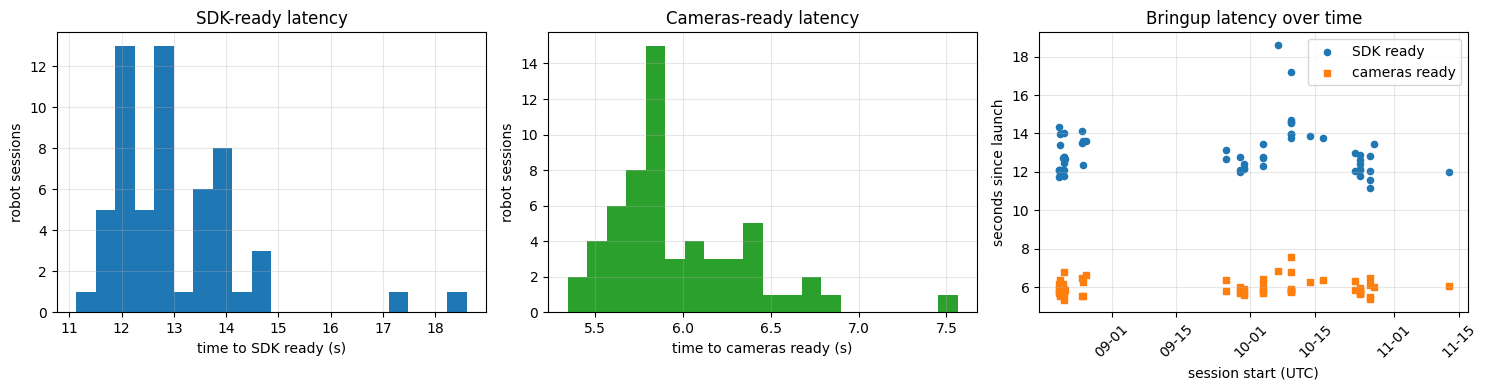

In [8]:
# @title 3a. Time to SDK ready and cameras ready: distributions and trend
def q(s): return pd.Series({"n": s.notna().sum(), "median": s.median(), "p95": s.quantile(.95), "min": s.min(), "max": s.max()})
print(pd.DataFrame({"time_to_sdk_ready_s": q(R["time_to_sdk_ready_s"]), "time_to_cameras_ready_s": q(R["time_to_cameras_ready_s"])}).round(2))
mt3 = R.groupby("month").agg(n=("session_id", "size"), sdk_med=("time_to_sdk_ready_s", "median"), cam_med=("time_to_cameras_ready_s", "median")).round(2)
print("\nMonthly medians:\n", mt3)
x = R["start_utc"].astype("int64") / 1e9
for col in ["time_to_sdk_ready_s", "time_to_cameras_ready_s"]:
    ok = R[col].notna()
    rho = pd.Series(x[ok].values).rank().corr(pd.Series(R.loc[ok, col].values).rank())  # Spearman = Pearson on ranks (no scipy)
    print(f"Spearman rho(start time, {col}) = {rho:.3f} (n={ok.sum()})")

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(R["time_to_sdk_ready_s"].dropna(), bins=20, color="tab:blue"); ax[0].set_xlabel("time to SDK ready (s)"); ax[0].set_ylabel("robot sessions"); ax[0].set_title("SDK-ready latency")
ax[1].hist(R["time_to_cameras_ready_s"].dropna(), bins=20, color="tab:green"); ax[1].set_xlabel("time to cameras ready (s)"); ax[1].set_ylabel("robot sessions"); ax[1].set_title("Cameras-ready latency")
tt = R.sort_values("start_utc")
ax[2].scatter(tt["start_utc"], tt["time_to_sdk_ready_s"], label="SDK ready", s=20)
ax[2].scatter(tt["start_utc"], tt["time_to_cameras_ready_s"], label="cameras ready", s=20, marker="s")
ax[2].set_xlabel("session start (UTC)"); ax[2].set_ylabel("seconds since launch"); ax[2].set_title("Bringup latency over time"); ax[2].legend()
ax[2].xaxis.set_major_formatter(mdates.DateFormatter("%m-%d")); plt.setp(ax[2].get_xticklabels(), rotation=45)
plt.tight_layout(); plt.show()

### 3b. Sessions that failed to reach SDK ready, and controller completeness

Failed bringups and controller completeness. **What it does:** lists robot sessions that never reached SDK ready and checks that all 10 controllers were loaded, configured and activated. **How to read it:** any row in the incomplete table is a bringup that did not finish. **Caveat:** a session that is killed early (ros2_control_node abort) cannot activate its controllers, so incompleteness usually mirrors section 4.

In [9]:
# @title 3b. Sessions that failed to reach SDK ready, and controller completeness
nok = R[~R["sdk_ready"]]
print(f"Robot sessions that never reached SDK ready: {len(nok)} of {len(R)}")
print(nok[["session_id", "duration_s", "cameras_ready", "kinematics_ready", "cn_death", "n_controllers_activated"]].to_string(index=False))
print("\nReady-milestone completeness (robot sessions):")
print(R[["sdk_ready", "cameras_ready", "kinematics_ready"]].sum().rename("sessions_true").to_frame().T)
print("\nControllers loaded/configured/activated (counts of sessions):")
print(R.groupby(["n_controllers_loaded", "n_controllers_configured", "n_controllers_activated"]).size().rename("sessions"))
inc = R[(R["n_controllers_activated"] < R["n_controllers_loaded"]) | (R["n_controllers_loaded"] < 10)]
print("\nIncomplete controller sessions:")
print(inc[["session_id", "duration_s", "n_controllers_loaded", "n_controllers_configured", "n_controllers_activated", "sdk_ready", "cn_death"]].to_string(index=False))
for sid in inc["session_id"]:
    c = CL[CL["session_id"] == sid]
    miss = c[c["activated_epoch"].isna()]["controller"].tolist()
    print(f"  {sid[:16]}: controllers never activated: {miss}")

Robot sessions that never reached SDK ready: 1 of 59
                                         session_id  duration_s  cameras_ready  kinematics_ready  cn_death  n_controllers_activated
2026-10-03-19-34-20-906968-reachy-2023-R0027-449267      20.557           True              True      True                        5

Ready-milestone completeness (robot sessions):
               sdk_ready  cameras_ready  kinematics_ready
sessions_true         58             59                59

Controllers loaded/configured/activated (counts of sessions):
n_controllers_loaded  n_controllers_configured  n_controllers_activated
6                     5                         5                           1
10                    10                        10                         58
Name: sessions, dtype: int64

Incomplete controller sessions:
                                         session_id  duration_s  n_controllers_loaded  n_controllers_configured  n_controllers_activated  sdk_ready  cn_death
2026-10-

## 4. Process deaths

**What it does.** Lists every process that died (from `processes`), grouped by executable and exit code, then looks at how long `ros2_control_node` lived before it died.

**How to read the output.** The table gives deaths, number of affected sessions and median uptime per (executable, exit code). Exit `-6` = SIGABRT (abort); `hal` exit 1 and `rplidar_scan_publisher` 255 belong to the mobile_base launches. The right-hand plot shows each `ros2_control_node` death as uptime before death (log scale): a cluster of deaths within ~20 s of start-up (start-up aborts) is very different from deaths after hours of running.

**Caveat.** Negative `uptime_s` values are clock-step artifacts (section 8); they are excluded from the plot and counted separately. The log does not say *why* the abort happened (the throttled bus-error windows in section 5 are only circumstantial).

            executable  exit_code  deaths  sessions  median_uptime_s
     ros2_control_node       -6.0      18        18            16.57
                   hal        1.0      13        13             1.62
rplidar_scan_publisher      255.0      13        13             0.26
         camera_server        1.0       2         2             3.66

Total processes 1278, died 46; end_reason counts:
end_reason
session_end         647
finished_cleanly    585
died                 46



ros2_control_node deaths: 18 (exit codes [np.float64(-6.0)]); negative uptime (clock step): 2
  early (<60 s after start): 8  | late (>=60 s): 8
  uptime before death: median 293 s; late deaths median 5.58 h, max 15.99 h
  early-death uptimes (s): [4.9, 7.5, 7.9, 10.3, 12.7, 15.7, 16.0, 17.1]


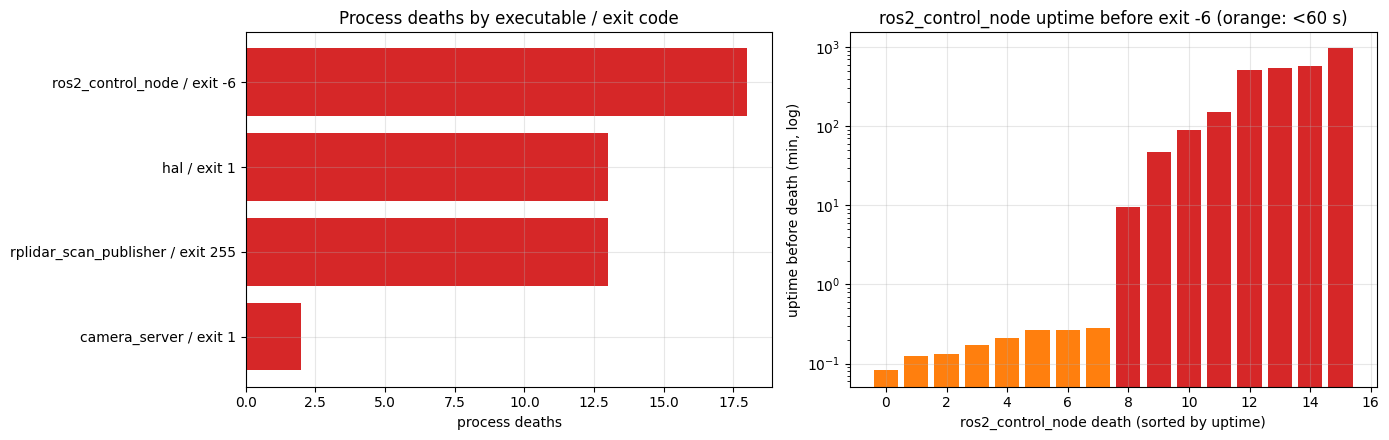

In [10]:
# @title 4. Process deaths by executable and exit code, uptime before ros2_control_node death
dd = (died.groupby(["executable", "exit_code"], dropna=False)
          .agg(deaths=("pid", "size"), sessions=("session_id", "nunique"), median_uptime_s=("uptime_s", "median"))
          .reset_index().sort_values("deaths", ascending=False))
print(dd.round(2).to_string(index=False))
print(f"\nTotal processes {len(P)}, died {len(died)}; end_reason counts:\n{P['end_reason'].value_counts().to_string()}")

cd = cn_death.merge(R[["session_id", "start_utc", "uptime_h", "total_w", "neck_w", "sdk_ready"]], on="session_id", suffixes=("", "_s"))
neg = cd[cd["uptime_s"] < 0]
cdv = cd[cd["uptime_s"] >= 0].sort_values("uptime_s")
early = cdv[cdv["uptime_s"] < 60]; late = cdv[cdv["uptime_s"] >= 60]
print(f"\nros2_control_node deaths: {len(cd)} (exit codes {sorted(cd['exit_code'].unique())}); negative uptime (clock step): {len(neg)}")
print(f"  early (<60 s after start): {len(early)}  | late (>=60 s): {len(late)}")
print(f"  uptime before death: median {cdv['uptime_s'].median():.0f} s; late deaths median {late['uptime_s'].median()/3600:.2f} h, max {late['uptime_s'].max()/3600:.2f} h")
print(f"  early-death uptimes (s): {early['uptime_s'].round(1).tolist()}")

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
lab = dd["executable"] + " / exit " + dd["exit_code"].astype(int).astype(str)
ax[0].barh(lab[::-1], dd["deaths"][::-1], color="tab:red"); ax[0].set_xlabel("process deaths"); ax[0].set_title("Process deaths by executable / exit code")
ax[1].bar(range(len(cdv)), cdv["uptime_s"] / 60, color=np.where(cdv["uptime_s"] < 60, "tab:orange", "tab:red"))
ax[1].set_yscale("log"); ax[1].set_xlabel("ros2_control_node death (sorted by uptime)"); ax[1].set_ylabel("uptime before death (min, log)")
ax[1].set_title("ros2_control_node uptime before exit -6 (orange: <60 s)")
plt.tight_layout(); plt.show()

## 5. Hardware bus error windows

**What it does.** Counts the throttled `hw_errors` windows by ros2_control *system* (ArmSystem = r_arm, HeadSystem = antennas, NeckSystem = Orbita neck) and error *signal*, ranks sessions by windows per uptime hour, shows when in a session the windows occur, the daily trend, and a separate NeckSystem view.

**How to read the output.** The heatmap cell value is the number of 30 s windows (log colour scale). Throttling caps each (system, signal) at 120 windows/hour, so a rate near that ceiling means "continuously failing". The session-profile histogram shows whether errors start immediately (start-up) or build up over time. NeckSystem matters most for perception: it carries the head orientation used for camera-to-robot grounding.

**Caveat.** Rows are windows, not errors; they are logged at INFO. Rates use launch.log uptime as the denominator, and sessions with tiny uptime are excluded from rankings (< 0.05 h).

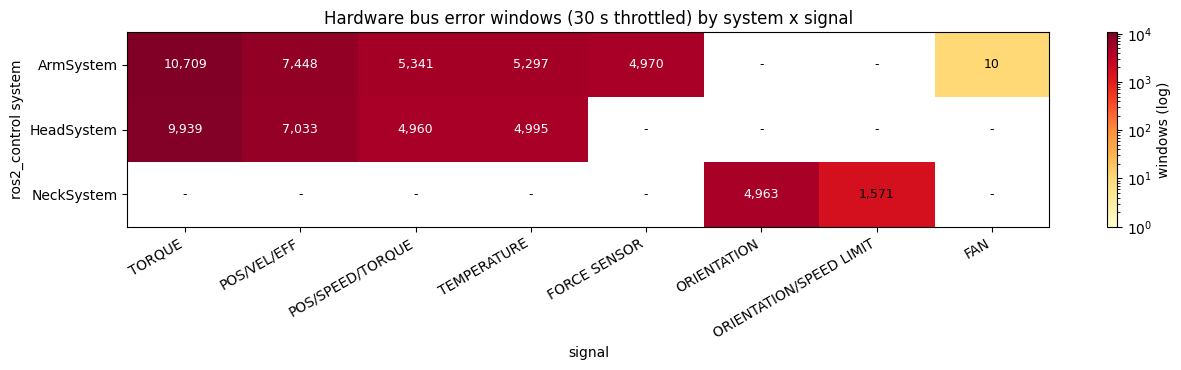

            windows  sessions  share_%
system                                
ArmSystem     33775        44     50.2
HeadSystem    26927        27     40.0
NeckSystem     6534        17      9.7

By op:
 op           READ  WRITE
system                  
ArmSystem   22994  10781
HeadSystem  17001   9926
NeckSystem   4963   1571

Top signals (system, signal):
 system      signal          
ArmSystem   TORQUE              10709
HeadSystem  TORQUE               9939
ArmSystem   POS/VEL/EFF          7448
HeadSystem  POS/VEL/EFF          7033
ArmSystem   POS/SPEED/TORQUE     5341
            TEMPERATURE          5297

Total windows 67,236 over 95.2 robot uptime hours = 706 windows/h


In [11]:
# @title 5a. Heatmap of error windows: system x signal (annotated)
hm = HW.groupby(["system", "signal"]).size().unstack(fill_value=0).reindex(["ArmSystem", "HeadSystem", "NeckSystem"])
hm = hm[hm.sum().sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(13, 3.8))
vals = hm.values.astype(float); vals_m = np.ma.masked_where(vals == 0, vals)
im = ax.imshow(vals_m, cmap="YlOrRd", norm=LogNorm(vmin=1, vmax=vals.max()), aspect="auto")
ax.set_xticks(range(hm.shape[1])); ax.set_xticklabels(hm.columns, rotation=30, ha="right"); ax.set_yticks(range(hm.shape[0])); ax.set_yticklabels(hm.index)
for i in range(hm.shape[0]):
    for j in range(hm.shape[1]):
        v = int(vals[i, j]); ax.text(j, i, f"{v:,}" if v else "-", ha="center", va="center", fontsize=9, color="white" if v > 3000 else "black")
ax.grid(False); ax.set_xlabel("signal"); ax.set_ylabel("ros2_control system"); ax.set_title("Hardware bus error windows (30 s throttled) by system x signal")
plt.colorbar(im, ax=ax, label="windows (log)"); plt.tight_layout(); plt.show()
bysys = HW.groupby("system").agg(windows=("epoch", "size"), sessions=("session_id", "nunique"))
bysys["share_%"] = (100 * bysys["windows"] / bysys["windows"].sum()).round(1)
print(bysys); print("\nBy op:\n", HW.groupby(["system", "op"]).size().unstack(fill_value=0))
print("\nTop signals (system, signal):\n", HW.groupby(["system", "signal"]).size().sort_values(ascending=False).head(6).to_string())
print(f"\nTotal windows {len(HW):,} over {R['uptime_h'].sum():.1f} robot uptime hours = {len(HW)/R['uptime_h'].sum():.0f} windows/h")

### 5b. Error-window rate per uptime hour: top sessions (red = ros2_control_node died)

Error-window rate per uptime hour. **What it does:** ranks sessions by throttled windows per uptime hour (uptime >= 0.05 h) and colours bars by whether ros2_control_node died. **How to read it:** rates near the throttle ceiling mean continuously failing buses. **Caveat:** windows, not individual errors; tiny sessions are excluded.

                                          session_id  uptime_h  total_w  w_per_h  arm_w  head_w  neck_w  cn_death
  2026-10-13-21-28-11-876815-reachy-2023-R0027-58694      9.70    14310  1475.39   6625    5494    2191      True
2026-10-06-22-36-28-980717-reachy-2023-R0027-2034445      8.65    11689  1351.76   5896    4827     966      True
2026-10-16-20-15-00-752231-reachy-2023-R0027-1087949     15.99    21034  1315.38  10579    8739    1716      True
 2026-10-24-19-32-52-780765-reachy-2023-R0027-212432      8.93    11096  1242.87   5546    4625     925      True
 2026-10-03-19-58-35-792689-reachy-2023-R0027-505700      1.48     1318   887.74    646     570     102      True
 2026-08-25-21-16-24-980200-reachy-2023-R0027-724377      2.52     1964   778.05   1049     785     130      True
   2026-10-09-21-58-44-548859-reachy-2023-R0027-2048      0.78      513   653.59    269     210      34      True
 2026-08-20-17-25-47-077902-reachy-2023-R0027-100618      2.19     1063   484.38    511 

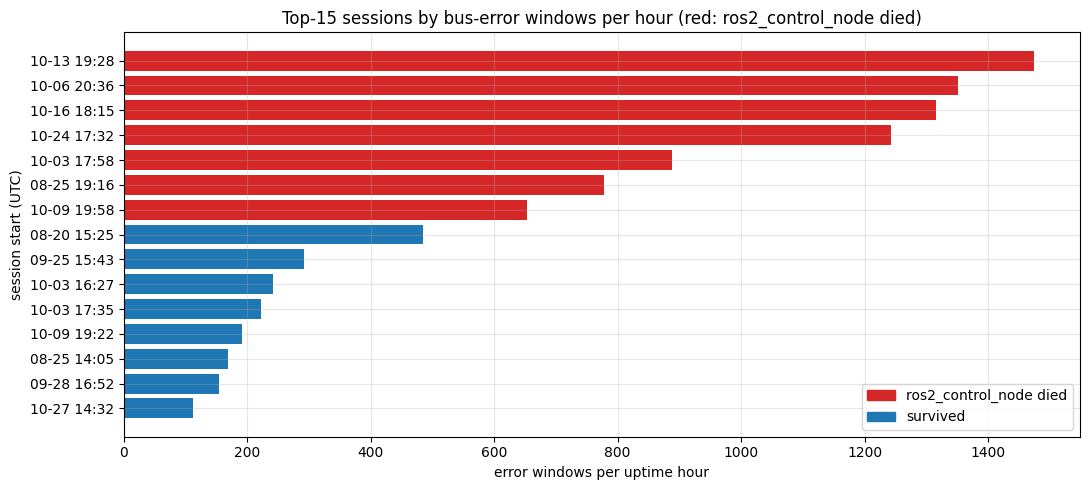


Sessions (>=0.05 h) with any windows: 20 of 21; median rate among them: 231.8 /h


In [12]:
# @title 5b. Error-window rate per uptime hour: top sessions (red = ros2_control_node died)
cand = R[(R["total_w"] > 0) & (R["uptime_h"] >= 0.05)].sort_values("w_per_h", ascending=False)
top = cand.head(15)
print(top[["session_id", "uptime_h", "total_w", "w_per_h", "arm_w", "head_w", "neck_w", "cn_death"]].round(2).to_string(index=False))
fig, ax = plt.subplots(figsize=(11, 5))
ax.barh([f"{d:%m-%d %H:%M}" for d in top["start_utc"]][::-1], top["w_per_h"][::-1],
        color=np.where(top["cn_death"], "tab:red", "tab:blue")[::-1])
ax.set_xlabel("error windows per uptime hour"); ax.set_ylabel("session start (UTC)")
ax.set_title("Top-15 sessions by bus-error windows per hour (red: ros2_control_node died)")
ax.legend(handles=[Patch(color="tab:red", label="ros2_control_node died"), Patch(color="tab:blue", label="survived")])
plt.tight_layout(); plt.show()
print(f"\nSessions (>=0.05 h) with any windows: {len(cand)} of {int((R['uptime_h']>=0.05).sum())}; median rate among them: {cand['w_per_h'].median():.1f} /h")

### 5c. Time-of-session profile of error windows

Time-of-session profile. **What it does:** histograms `s_since_session_start` of windows overall and for the first 5 minutes by system. **How to read it:** a spike at the start means start-up errors; a flat tail means errors persist for hours. **Caveat:** few sessions are very long, so late-session counts reflect those sessions only.

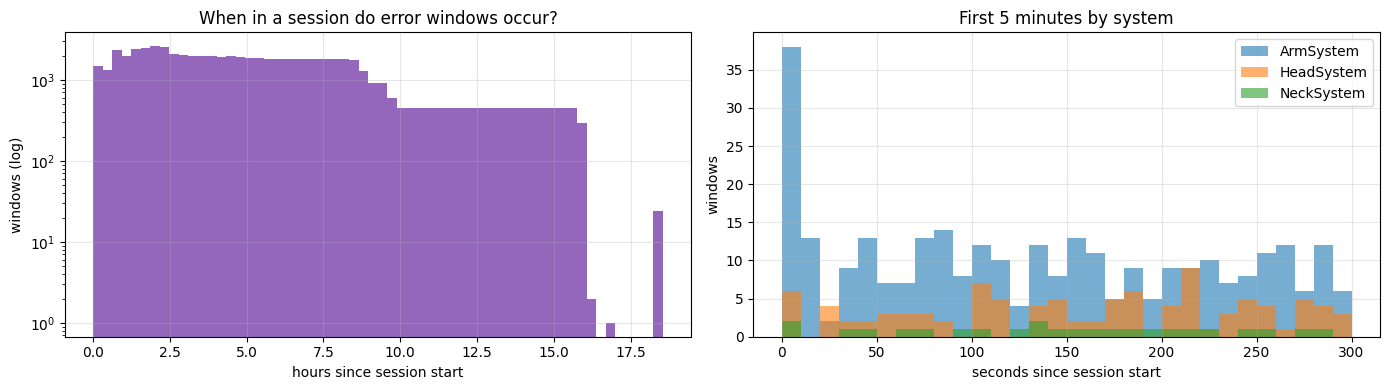

s_since_session_start quantiles (s):
 0.01      473.0
0.10     4275.0
0.50    18235.0
0.90    40736.0
0.99    55876.0

First window per session (s since start), by system:
            count  min    50%      max
system                                
ArmSystem    44.0  3.8    7.0  15836.4
HeadSystem   27.0  4.7  103.0   3132.4
NeckSystem   17.0  4.3  766.6  66374.7


In [13]:
# @title 5c. Time-of-session profile of error windows
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].hist(HW["s_since_session_start"] / 3600, bins=60, color="tab:purple"); ax[0].set_yscale("log")
ax[0].set_xlabel("hours since session start"); ax[0].set_ylabel("windows (log)"); ax[0].set_title("When in a session do error windows occur?")
first = HW[HW["s_since_session_start"] <= 300]
for sysn, c in zip(["ArmSystem", "HeadSystem", "NeckSystem"], ["tab:blue", "tab:orange", "tab:green"]):
    ax[1].hist(first.loc[first["system"] == sysn, "s_since_session_start"], bins=np.arange(0, 305, 10), alpha=0.6, label=sysn, color=c)
ax[1].set_xlabel("seconds since session start"); ax[1].set_ylabel("windows"); ax[1].set_title("First 5 minutes by system"); ax[1].legend()
plt.tight_layout(); plt.show()
print("s_since_session_start quantiles (s):\n", HW["s_since_session_start"].quantile([.01, .1, .5, .9, .99]).round(0).to_string())
print("\nFirst window per session (s since start), by system:")
print(HW.groupby(["session_id", "system"])["s_since_session_start"].min().groupby("system").describe()[["count", "min", "50%", "max"]].round(1))

### 5d. Daily trend and separate NeckSystem / ArmSystem / HeadSystem views

Daily trend and the NeckSystem / ArmSystem / HeadSystem split. **What it does:** daily bar charts per system and a neck-specific summary (share of robot sessions affected, windows per uptime hour). **How to read it:** neck windows matter most for camera-to-robot grounding. **Caveat:** very short sessions give huge per-hour rates from a single window; look at counts and uptime together.

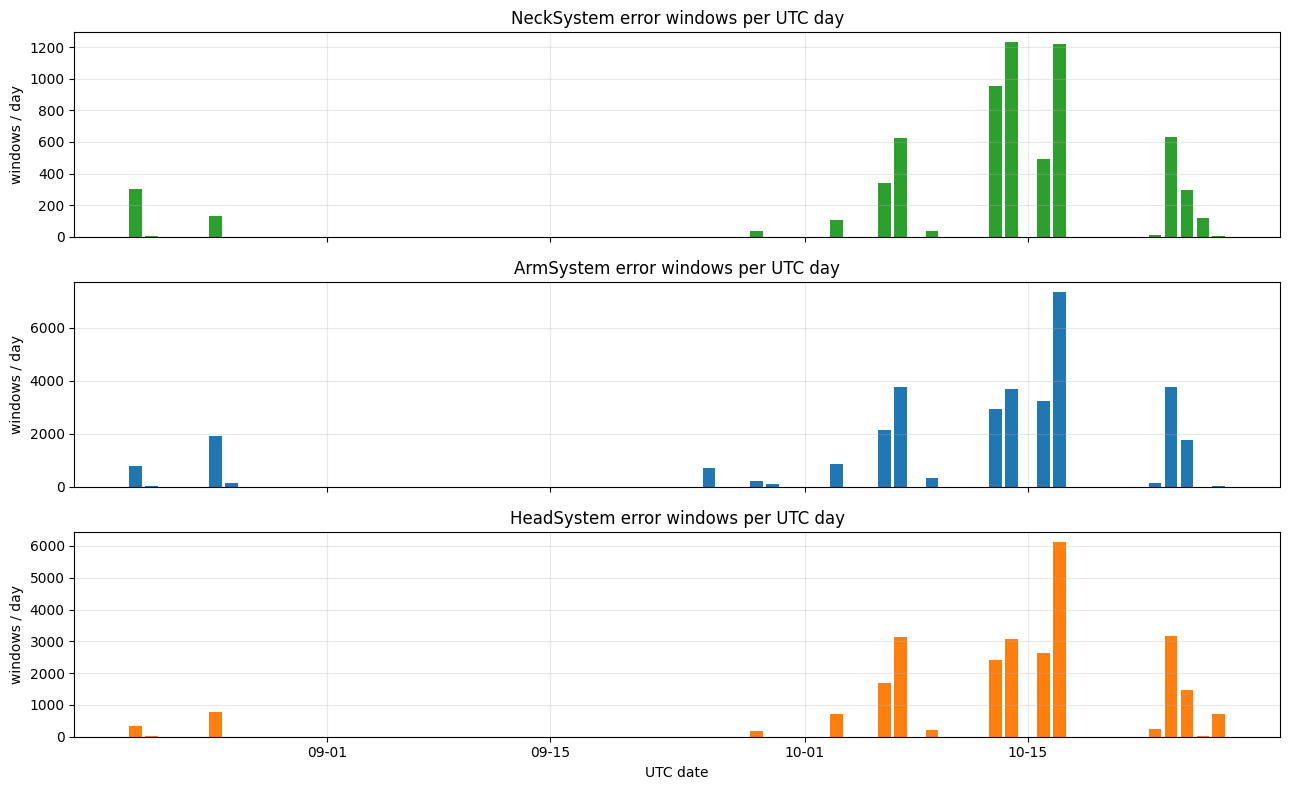

NeckSystem: 6,534 windows in 17 of 59 robot sessions (28.8%); 68.7 windows per robot uptime hour overall, 86.2 per hour in affected sessions
Share of robot UPTIME in sessions with neck windows: 79.6%
                                          session_id  uptime_h  neck_w  neck_w_per_h  first_neck_s  cn_death
 2026-08-20-17-25-47-077902-reachy-2023-R0027-100618      2.19     268        122.12       1584.42     False
  2026-08-20-21-23-24-213243-reachy-2023-R0027-15190      0.01      25       4394.75         48.15     False
   2026-08-20-21-48-30-598756-reachy-2023-R0027-2169      0.01      10       1647.07        766.63     False
 2026-08-21-20-06-04-503305-reachy-2023-R0027-249639      0.01       2        193.49        138.75     False
 2026-08-25-21-16-24-980200-reachy-2023-R0027-724377      2.52     130         51.50       5090.28      True
  2026-09-28-18-20-55-157643-reachy-2023-R0027-18107      0.01      35       6077.85        311.49     False
 2026-10-03-19-58-35-792689-reachy-20

In [14]:
# @title 5d. Daily trend and separate NeckSystem / ArmSystem / HeadSystem views
days = pd.date_range(HW["date"].min(), HW["date"].max())
dsys = HW.groupby(["date", "system"]).size().unstack(fill_value=0).reindex(days, fill_value=0)
fig, ax = plt.subplots(3, 1, figsize=(13, 8), sharex=True)
for a, sysn, c in zip(ax, ["NeckSystem", "ArmSystem", "HeadSystem"], ["tab:green", "tab:blue", "tab:orange"]):
    a.bar(dsys.index, dsys.get(sysn, 0), color=c, width=0.8); a.set_ylabel("windows / day"); a.set_title(f"{sysn} error windows per UTC day")
ax[-1].set_xlabel("UTC date"); ax[-1].xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))
plt.tight_layout(); plt.show()

nk = R[R["neck_w"] > 0].sort_values("start_utc")
print(f"NeckSystem: {int(R['neck_w'].sum()):,} windows in {len(nk)} of {len(R)} robot sessions ({100*len(nk)/len(R):.1f}%); "
      f"{R['neck_w'].sum()/R['uptime_h'].sum():.1f} windows per robot uptime hour overall, "
      f"{nk['neck_w'].sum()/nk['uptime_h'].sum():.1f} per hour in affected sessions")
print(f"Share of robot UPTIME in sessions with neck windows: {100*nk['uptime_h'].sum()/R['uptime_h'].sum():.1f}%")
print(nk[["session_id", "uptime_h", "neck_w", "neck_w_per_h", "first_neck_s", "cn_death"]].round(2).to_string(index=False))
Rl5 = R[R["duration_s"] >= 60]
print(f"Among the {len(Rl5)} robot sessions >= 60 s: {int((Rl5['neck_w']>0).sum())} have NeckSystem windows; neck windows per uptime hour = {Rl5['neck_w'].sum()/Rl5['uptime_h'].sum():.1f}")
print("\nNeck signals:\n", HW[HW["system"] == "NeckSystem"].groupby(["op", "signal"]).size().to_string())

## 6. Bus-error windows vs `ros2_control_node` deaths

**What it does.** Compares error-window rates in robot sessions where `ros2_control_node` died against sessions where it survived, and measures the time between the last error window and the death.

**How to read the output.** Pooled rate = total windows / total uptime hours in each group; the median per session is also given. The strip plot shows each session's rate (symlog axis). `last window -> death` is `died_epoch - last error-window epoch`; a small value means errors were still being logged right before the abort. The second table restricts to sessions longer than 60 s to exclude start-up aborts.

**Caveat.** This is correlation, not cause: dying sessions are mostly the long ones, and the 20 s start-up aborts have essentially no error windows (so they are a different failure mode). Death time comes from launch.log and the window time from the node clock; in sessions with clock steps the delta can be off by the step size.

All robot sessions (cn_death = ros2_control_node died):
                          False     True 
sessions                  41.00     18.00
uptime_h                  46.91     48.27
windows                 5305.00  61931.00
pooled_w_per_h           113.10   1283.10
median_session_w_per_h   171.34    270.63
sessions_with_windows     33.00     12.00
neck_windows             470.00   6064.00
neck_w_per_h              10.02    125.64

Sessions >= 60 s only:
                          False     True 
sessions                  15.00      8.00
uptime_h                  46.75     48.22
windows                 4650.00  61925.00
pooled_w_per_h            99.46   1284.27
median_session_w_per_h   111.33   1065.30
sessions_with_windows     12.00      8.00
neck_windows             394.00   6064.00
neck_w_per_h               8.43    125.76

Deaths with at least one prior window: 12 of 18
                                          session_id  uptime_h  total_w  last_window_to_death_s
   2026-08-20-21-19

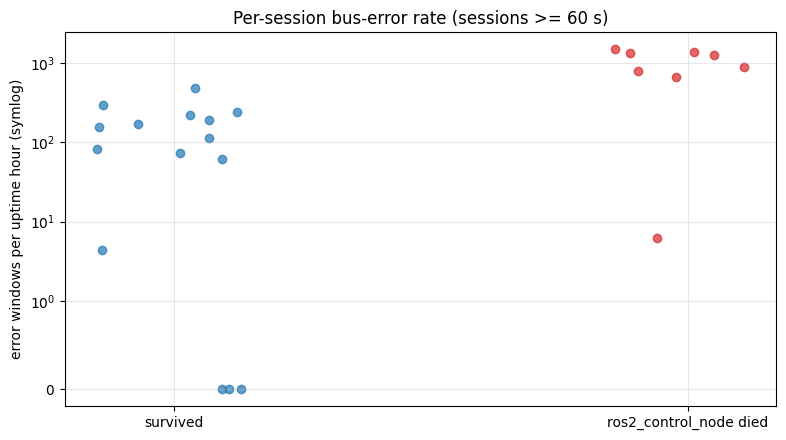

In [15]:
# @title 6. Error-window rate in dying vs surviving sessions; time from last window to death
def grp(df):
    return pd.Series({"sessions": len(df), "uptime_h": df["uptime_h"].sum(), "windows": df["total_w"].sum(),
                      "pooled_w_per_h": df["total_w"].sum() / df["uptime_h"].sum(),
                      "median_session_w_per_h": df["w_per_h"].median(),
                      "sessions_with_windows": int((df["total_w"] > 0).sum()),
                      "neck_windows": df["neck_w"].sum(), "neck_w_per_h": df["neck_w"].sum() / df["uptime_h"].sum()})
print("All robot sessions (cn_death = ros2_control_node died):")
print(pd.DataFrame({k: grp(g) for k, g in R.groupby("cn_death")}).round(2))
Rl = R[R["duration_s"] >= 60]
print("\nSessions >= 60 s only:")
print(pd.DataFrame({k: grp(g) for k, g in Rl.groupby("cn_death")}).round(2))

dt = R[R["cn_death"] & R["last_w_epoch"].notna()].merge(cn_death[["session_id", "died_epoch"]], on="session_id")
dt["last_window_to_death_s"] = dt["died_epoch"] - dt["last_w_epoch"]
print(f"\nDeaths with at least one prior window: {len(dt)} of {int(R['cn_death'].sum())}")
print(dt[["session_id", "uptime_h", "total_w", "last_window_to_death_s"]].round(1).to_string(index=False))
v = dt["last_window_to_death_s"]
print(f"median {v.median():.1f} s | min {v.min():.1f} | max {v.max():.1f} | within 60 s: {(v.abs() <= 60).sum()} of {len(v)}")

fig, ax = plt.subplots(figsize=(8, 4.5))
rng = np.random.default_rng(0)
for i, (k, g) in enumerate(Rl.groupby("cn_death")):
    ax.scatter(i + rng.uniform(-0.15, 0.15, len(g)), g["w_per_h"], alpha=0.7, color="tab:red" if k else "tab:blue")
ax.set_yscale("symlog", linthresh=1); ax.set_xticks([0, 1]); ax.set_xticklabels(["survived", "ros2_control_node died"])
ax.set_ylabel("error windows per uptime hour (symlog)"); ax.set_title("Per-session bus-error rate (sessions >= 60 s)")
plt.tight_layout(); plt.show()

## 7. Thermal proxy: fans

**What it does.** Uses the fan ON/OFF events (fan turns ON above a 45 C trigger) as a thermal proxy: ON events per fan per day, fan-ON duty (ON time / session duration) per session and fan, flapping detection (ON intervals shorter than `FLAP_S` seconds) and intervals still open at session end.

**How to read the output.** More ON events and a higher duty mean the joint was warm more of the time. Flapping (ON for ~1 s, then OFF, repeatedly) suggests temperature hovering at the threshold or a controller/thermal-reading problem. `FLAP_MIN` is the number of short intervals needed for a session/fan to count as "sustained flapping".

**Caveat.** Only the temperature trigger is observed, not temperatures. `fan_intervals` uses launch.log as the canonical source (node files only when launch has none). An interval still open at session end has `off` = session end.

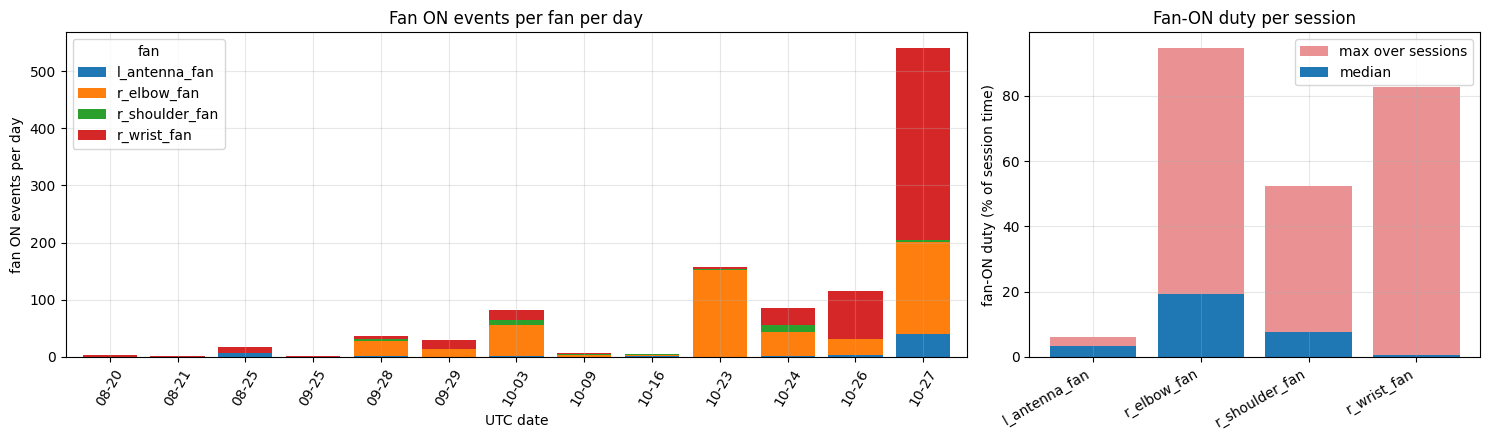

ON events per fan: {'r_wrist_fan': 511, 'r_elbow_fan': 482, 'l_antenna_fan': 57, 'r_shoulder_fan': 32} | sessions with any fan ON: 22

Duty by fan (%):
                 count  median    max
fan                                 
l_antenna_fan       8    3.29   6.06
r_elbow_fan        14   19.21  94.70
r_shoulder_fan     11    7.60  52.23
r_wrist_fan        20    0.64  82.75

Top 10 session/fan duty:
                                          session_id            fan  n_on     on_s  duration_s  duty_%
 2026-10-24-19-32-52-780765-reachy-2023-R0027-212432    r_elbow_fan    23 30437.83    32139.84   94.70
2026-10-27-15-32-59-694939-reachy-2023-R0027-1194059    r_elbow_fan    33 19257.96    21083.41   91.34
 2026-10-24-19-30-53-614966-reachy-2023-R0027-207888    r_wrist_fan     3    62.00       74.92   82.75
2026-10-23-16-38-29-212274-reachy-2023-R0027-1937041    r_elbow_fan   152 13892.00    19661.36   70.66
 2026-10-24-18-58-31-601586-reachy-2023-R0027-133722 r_shoulder_fan     3  1003.00  

In [16]:
# @title 7a. Fan ON events per fan per day and fan-ON duty per session
FI2 = FI.merge(S[["session_id", "launch_type"]], on="session_id", how="left")
FI2["date"] = FI2["on_utc"].dt.tz_localize(None).dt.normalize()
perday = FI2.groupby(["date", "fan"]).size().unstack(fill_value=0)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5), gridspec_kw={"width_ratios": [2, 1]})
perday.plot.bar(stacked=True, ax=ax[0], width=0.8)
ax[0].set_xticklabels([d.strftime("%m-%d") for d in perday.index], rotation=60); ax[0].set_xlabel("UTC date"); ax[0].set_ylabel("fan ON events per day"); ax[0].set_title("Fan ON events per fan per day")
duty = FI2.groupby(["session_id", "fan"]).agg(on_s=("duration_s", "sum"), n_on=("on_epoch", "size")).reset_index()
duty = duty.merge(S[["session_id", "duration_s", "start_utc"]], on="session_id")
duty["duty_%"] = 100 * duty["on_s"] / duty["duration_s"]
dfan = duty.groupby("fan")["duty_%"].agg(["count", "median", "max"]).round(2)
ax[1].bar(dfan.index, dfan["max"], color="tab:red", alpha=0.5, label="max over sessions"); ax[1].bar(dfan.index, dfan["median"], color="tab:blue", label="median")
ax[1].set_ylabel("fan-ON duty (% of session time)"); ax[1].set_title("Fan-ON duty per session"); ax[1].legend(); plt.setp(ax[1].get_xticklabels(), rotation=30, ha="right")
plt.tight_layout(); plt.show()
print("ON events per fan:", FI["fan"].value_counts().to_dict(), "| sessions with any fan ON:", FI["session_id"].nunique())
print("\nDuty by fan (%):\n", dfan)
print("\nTop 10 session/fan duty:")
print(duty.sort_values("duty_%", ascending=False).head(10)[["session_id", "fan", "n_on", "on_s", "duration_s", "duty_%"]].round(2).to_string(index=False))

### 7b. Fan flapping (short ON intervals) and intervals open at session end

Fan flapping and open intervals. **What it does:** counts ON intervals shorter than `FLAP_S` seconds per session and fan and lists intervals still open at session end. **How to read it:** many ~1 s ON intervals mean the fan toggles around the 45 C trigger. **Caveat:** thermal proxy only; tune `FLAP_S` / `FLAP_MIN` with the form fields.

ON intervals < 5 s: 126 of 1082 (11.6%); median duration 1.00 s
Session/fan pairs with any short ON: 25 | sustained (>= 5): 8
Sessions with any flapping: 18 | sustained flapping sessions: 7
Short ON intervals by fan: {'r_wrist_fan': 112, 'r_elbow_fan': 13, 'r_shoulder_fan': 1}
         session         fan  n_short_on  uptime_h  sustained
2026-10-26-20-54 r_wrist_fan          42     18.56       True
2026-10-26-19-23 r_wrist_fan          13      1.46       True
2026-08-25-21-16 r_wrist_fan           8      2.52       True
2026-10-26-20-54 r_elbow_fan           8     18.56       True
2026-09-29-18-42 r_wrist_fan           8      1.37       True
2026-10-27-15-32 r_wrist_fan           7      5.86       True
2026-10-24-18-58 r_wrist_fan           7      0.53       True
2026-10-03-18-27 r_wrist_fan           5      1.01       True
2026-10-03-19-35 r_wrist_fan           4      0.38      False
2026-08-20-17-25 r_wrist_fan           4      2.19      False
2026-08-25-16-05 r_wrist_fan           4

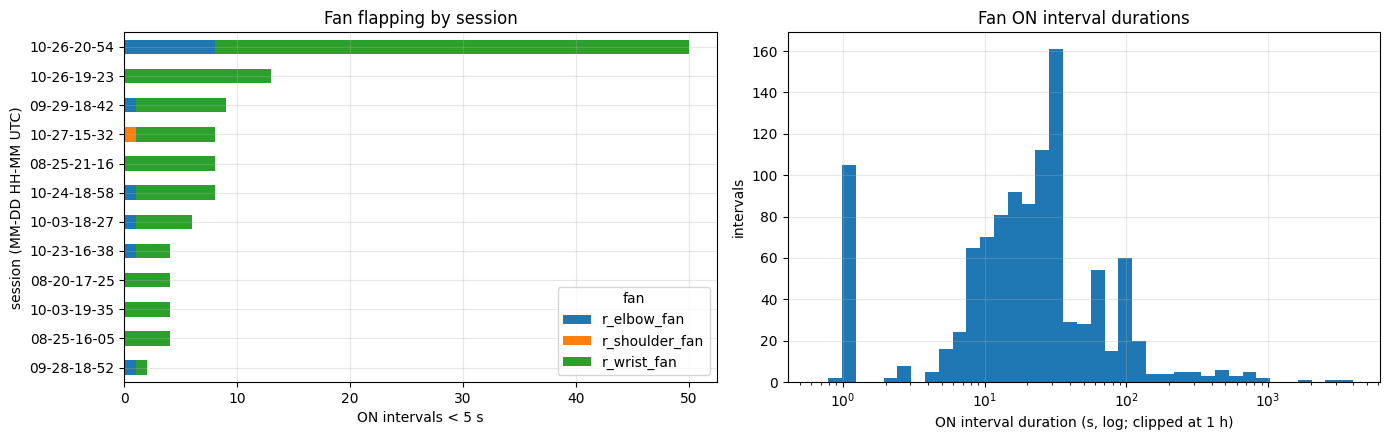


Intervals still open at session end: 7
                                         session_id            fan                           on_utc  on_for_s  session_s
 2026-09-28-18-52-39-538394-reachy-2023-R0027-93954    r_elbow_fan 2026-09-28 19:06:35.963000+00:00     137.0     8173.0
 2026-09-29-18-42-40-477832-reachy-2023-R0027-33782    r_elbow_fan 2026-09-29 18:04:50.860000+00:00       0.0     4930.0
  2026-10-09-21-58-44-548859-reachy-2023-R0027-2048 r_shoulder_fan 2026-10-09 20:27:05.354000+00:00    1125.0     2826.0
2026-10-24-18-58-31-601586-reachy-2023-R0027-133722    r_wrist_fan 2026-10-24 17:30:10.776000+00:00      21.0     1920.0
2026-10-24-19-30-53-614966-reachy-2023-R0027-207888    r_wrist_fan 2026-10-24 17:31:55.538000+00:00      13.0       75.0
2026-10-24-19-30-53-614966-reachy-2023-R0027-207888 r_shoulder_fan 2026-10-24 17:32:08.538000+00:00       0.0       75.0
2026-10-24-19-32-52-780765-reachy-2023-R0027-212432    r_elbow_fan 2026-10-24 18:27:07.790000+00:00   28885.0    

In [17]:
# @title 7b. Fan flapping (short ON intervals) and intervals open at session end
FLAP_S = 5      # @param {type:"number"}
FLAP_MIN = 5    # @param {type:"integer"}
short = FI[(FI["closed"]) & (FI["duration_s"] < FLAP_S)]
fl = short.groupby(["session_id", "fan"]).size().rename("n_short_on").reset_index()
fl["sustained"] = fl["n_short_on"] >= FLAP_MIN
print(f"ON intervals < {FLAP_S} s: {len(short)} of {len(FI)} ({100*len(short)/len(FI):.1f}%); median duration {short['duration_s'].median():.2f} s")
print(f"Session/fan pairs with any short ON: {len(fl)} | sustained (>= {FLAP_MIN}): {int(fl['sustained'].sum())}")
print(f"Sessions with any flapping: {fl['session_id'].nunique()} | sustained flapping sessions: {fl.loc[fl['sustained'],'session_id'].nunique()}")
print("Short ON intervals by fan:", short["fan"].value_counts().to_dict())
fl2 = fl.merge(S[["session_id", "start_utc", "uptime_h"]], on="session_id").sort_values("n_short_on", ascending=False)
print(fl2.head(12).assign(session=lambda d: d["session_id"].str[:16]).drop(columns="session_id")[["session", "fan", "n_short_on", "uptime_h", "sustained"]].round(2).to_string(index=False))

pivot = fl.pivot_table(index="session_id", columns="fan", values="n_short_on", fill_value=0)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
pivot.assign(t=pivot.sum(axis=1)).sort_values("t", ascending=False).drop(columns="t").head(12).rename(index=lambda s: s[5:16]).plot.barh(stacked=True, ax=ax[0])
ax[0].invert_yaxis(); ax[0].set_xlabel(f"ON intervals < {FLAP_S} s"); ax[0].set_ylabel("session (MM-DD HH-MM UTC)"); ax[0].set_title("Fan flapping by session")
ax[1].hist(FI.loc[FI["closed"], "duration_s"].clip(upper=3600), bins=np.logspace(-0.2, 3.6, 40)); ax[1].set_xscale("log")
ax[1].set_xlabel("ON interval duration (s, log; clipped at 1 h)"); ax[1].set_ylabel("intervals"); ax[1].set_title("Fan ON interval durations")
plt.tight_layout(); plt.show()
op = FI[~FI["closed"]].merge(S[["session_id", "launch_type", "duration_s"]], on="session_id")
print(f"\nIntervals still open at session end: {len(op)}")
print(op[["session_id", "fan", "on_utc", "duration_s_x", "duration_s_y"]].rename(columns={"duration_s_x": "on_for_s", "duration_s_y": "session_s"}).round(0).to_string(index=False))

## 8. Clock integrity

**What it does.** Lists the sessions where the robot wall-clock stepped backwards (`n_clock_steps_back`, `clock_step_back_s`) and the knock-on effects visible in the data (negative process uptimes).

**How to read the output.** Each row is a session with a backward step, the total step size and the process uptimes that went negative. The ETL adds detected steps back into `duration_s` and `time_to_*`, but `start_utc` and other absolute stamps stay raw.

**Why it matters for the project.** Camera frames, neck poses and arm states that are time-stamped by the robot clock will be shifted by up to the step size relative to a session start recorded before the step (and relative to a capture PC). Anything that correlates log events with capture timestamps should (a) discard or re-align the seconds around the step, and (b) prefer monotonic/ROS time stamped in the same stream.

**Caveat.** Steps are detected on non-spam lines only, so `mobile_base` sessions are under-detected.

Sessions with clock steps back: 4 of 73 (robot sessions: 4); total stepped back: 109.1 s
                                       session_id   launch_type                        start_utc  duration_s  n_clock_steps_back  clock_step_back_s
2026-08-20-16-44-45-356478-reachy-2023-R0027-1918 robot_bringup 2026-08-20 14:44:45.359000+00:00       21.73                   1              12.86
2026-08-25-16-04-36-760623-reachy-2023-R0027-2119 robot_bringup 2026-08-25 14:04:36.762000+00:00       13.64                   1               1.65
2026-09-25-17-07-03-603579-reachy-2023-R0027-2054 robot_bringup 2026-09-25 15:07:03.605000+00:00       12.98                   1              64.34
2026-11-12-21-29-14-130092-reachy-2023-R0027-1866 robot_bringup 2026-11-12 20:29:14.132000+00:00       12.09                   1              30.26

Processes with negative uptime (artifact of the step): 23
                                       session_id              executable  uptime_s  exit_code
2026-08-20-16-44-

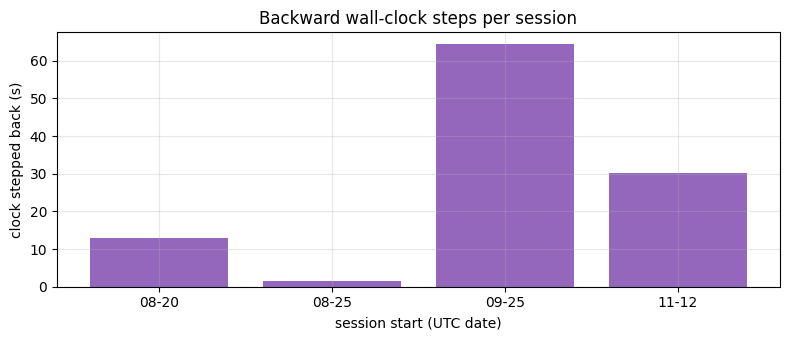

In [18]:
# @title 8. Sessions with backward clock steps and their effects
cs = S[S["n_clock_steps_back"] > 0][["session_id", "launch_type", "start_utc", "duration_s", "n_clock_steps_back", "clock_step_back_s"]]
print(f"Sessions with clock steps back: {len(cs)} of {len(S)} (robot sessions: {int((cs['launch_type']=='robot_bringup').sum())}); total stepped back: {cs['clock_step_back_s'].sum():.1f} s")
print(cs.round(2).to_string(index=False))
negp = P[P["uptime_s"] < 0][["session_id", "executable", "uptime_s", "exit_code"]]
print(f"\nProcesses with negative uptime (artifact of the step): {len(negp)}"); print(negp.round(1).to_string(index=False))
neg_hw = HW[HW["s_since_session_start"] < 0]
print(f"\nhw windows with negative s_since_session_start: {len(neg_hw)}")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar([f"{d:%m-%d}" for d in cs["start_utc"]], cs["clock_step_back_s"], color="tab:purple")
ax.set_xlabel("session start (UTC date)"); ax.set_ylabel("clock stepped back (s)"); ax.set_title("Backward wall-clock steps per session")
plt.tight_layout(); plt.show()

## 9. Message templates

**What it does.** Ranks normalised message templates (hex/numbers replaced by `N`) excluding the `SetSpeed` spam, shows counts by level and category, lists rare templates (count <= 3) as an anomaly list and summarises tracebacks, warnings and ERROR lines.

**How to read the output.** `count_canon` avoids the launch/node double count: for `hw_bus_error` it is the node count (those lines exist only in ros2_control_node files), for everything else the launch count (node count if launch has none). In the rare-template table, rows flagged `torn=True` are heuristically-detected truncated lines (a process killed mid-write), which are artifacts, not real events; the remaining rows are the interesting anomalies.

**Caveat.** Level is NaN for continuation lines such as traceback text. The torn heuristic (short, no terminating punctuation) is approximate.

templates: 310 (spam templates removed: 1, spam count 5,030,000)
                                   template level       node     category  count_canon  n_sessions
            (r_arm) READ POS/VEL/EFF ERROR!  INFO  ArmSystem hw_bus_error         7448          43
         (antennas) READ POS/VEL/EFF ERROR!  INFO HeadSystem hw_bus_error         7033          27
                (r_arm) WRITE TORQUE ERROR!  INFO  ArmSystem hw_bus_error         5430          25
      (r_arm) WRITE POS/SPEED/TORQUE ERROR!  INFO  ArmSystem hw_bus_error         5341          25
            (r_arm) READ TEMPERATURE ERROR!  INFO  ArmSystem hw_bus_error         5297          24
                 (r_arm) READ TORQUE ERROR!  INFO  ArmSystem hw_bus_error         5279          24
         (antennas) READ TEMPERATURE ERROR!  INFO HeadSystem hw_bus_error         4995          13
              (antennas) READ TORQUE ERROR!  INFO HeadSystem hw_bus_error         4973          12
           (r_arm) READ FORCE SENSOR ERROR! 

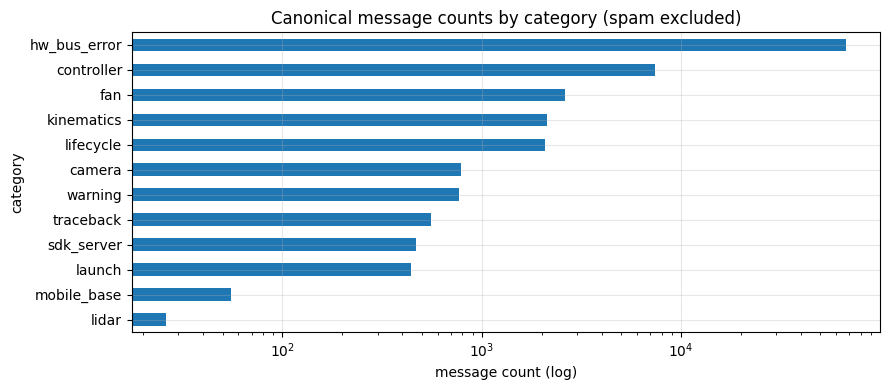

In [19]:
# @title 9a. Top templates excluding spam; counts by level and category
M = MT.copy()
spam_mask = M["template"].str.contains("SetSpeed not available", na=False)
M["count_canon"] = np.where(M["category"] == "hw_bus_error", M["count_node"], np.where(M["count_launch"] > 0, M["count_launch"], M["count_node"]))
Mx = M[~spam_mask]
print(f"templates: {len(M)} (spam templates removed: {int(spam_mask.sum())}, spam count {int(M.loc[spam_mask,'count'].sum()):,})")
print(Mx.sort_values("count_canon", ascending=False).head(15)[["template", "level", "node", "category", "count_canon", "n_sessions"]].to_string(index=False))
lc = Mx.fillna({"level": "(none)"}).pivot_table(index="category", columns="level", values="count_canon", aggfunc="sum", fill_value=0)
lc["total"] = lc.sum(axis=1); lc = lc.sort_values("total", ascending=False)
print("\nCanonical counts by category x level:\n", lc)
fig, ax = plt.subplots(figsize=(9, 4))
lc["total"].iloc[::-1].plot.barh(ax=ax, color="tab:blue"); ax.set_xscale("log"); ax.set_xlabel("message count (log)"); ax.set_ylabel("category"); ax.set_title("Canonical message counts by category (spam excluded)")
plt.tight_layout(); plt.show()

### 9b. Rare templates (count <= 3) as an anomaly list

Rare templates as an anomaly list. **What it does:** lists templates seen at most `RARE_MAX` times and flags likely torn (truncated) lines. **How to read it:** non-torn rows are real one-off events (e.g. the camera_server port-bind failure). **Caveat:** the torn-line test is a heuristic.

In [20]:
# @title 9b. Rare templates (count <= 3) as an anomaly list
RARE_MAX = 3  # @param {type:"integer"}
rare = Mx[Mx["count"] <= RARE_MAX].copy()
rare["torn"] = ((rare["template"].str.len() < 60) & (~rare["template"].str.contains(r"[!.)\]'\"]$", regex=True)) & rare["level"].notna()) | rare["template"].str.match(r"^\(\w+\)\s*\w{0,6}$")
rare["first_utc"] = rare["first_utc"].dt.strftime("%Y-%m-%d %H:%M")
print(f"Rare templates (count <= {RARE_MAX}): {len(rare)} | likely torn fragments: {int(rare['torn'].sum())} | real: {int((~rare['torn']).sum())}")
real = rare[~rare["torn"]].sort_values("first_utc")
print("\nNon-torn rare templates:")
print(real[["first_utc", "level", "category", "count", "template"]].assign(template=lambda d: d["template"].str.slice(0, 110)).to_string(index=False))
print("\nTorn fragments by category:", rare[rare["torn"]]["category"].value_counts().to_dict())

Rare templates (count <= 3): 39 | likely torn fragments: 26 | real: 13

Non-torn rare templates:
       first_utc level  category  count                                                                                                       template
2026-08-21 18:05   NaN traceback      2                                               raise RuntimeError(_ERROR_MESSAGE_PORT_BINDING_FAILED % address)
2026-08-21 18:05   NaN traceback      2                                                                   return _common.validate_port_binding_result(
2026-08-21 18:05   NaN traceback      2                                                                             server.add_insecure_port('[::]:N')
2026-08-21 18:05   NaN traceback      2                          sys.exit(load_entry_point('reachy-sdk-server', 'console_scripts', 'camera_server')())
2026-08-21 18:05   NaN traceback      2   File "/home/reachy/.local/lib/python3.N/site-packages/grpc/_common.py", line N, in validate_port_binding_r

### 9c. Tracebacks, warnings and ERROR lines summary

Tracebacks, warnings and ERROR lines. **What it does:** summarises launch-sourced traceback, warning and ERROR lines. **How to read it:** most tracebacks come from the failing mobile_base launches; robot-session tracebacks are the ones that matter. **Caveat:** continuation lines have no level or node.

In [21]:
# @title 9c. Tracebacks, warnings and ERROR lines summary
E1 = EV[EV["source_kind"] == "launch"]
print("Launch-sourced events by category (canonical):"); print(E1["category"].value_counts().to_string())
tb = E1[E1["category"] == "traceback"]
tb_last = tb[~tb["message"].str.startswith(("File ", "  File "), na=False)]
print(f"\nTraceback lines: {len(tb)} in {tb['session_id'].nunique()} sessions; exception lines (not 'File ...'):")
print(tb_last["template"].str.slice(0, 120).value_counts().head(8).to_string())
wn = E1[E1["category"] == "warning"]
print(f"\nWarning lines: {len(wn)} in {wn['session_id'].nunique()} sessions"); print(wn["template"].str.slice(0, 100).value_counts().head(5).to_string())
er = EV[(EV["level"] == "ERROR") & (EV["source_kind"] == "launch")]
print(f"\nERROR-level launch lines: {len(er)}")
print(er.assign(t=er["template"].str.slice(0, 90)).groupby("t").agg(n=("epoch", "size"), sessions=("session_id", "nunique"), first=("ts_utc", "min")).sort_values("n", ascending=False).head(10).to_string())
print("\nTraceback sessions by launch type:", S[S["session_id"].isin(tb["session_id"])]["launch_type"].value_counts().to_dict())

Launch-sourced events by category (canonical):
category
fan            2629
kinematics     2124
lifecycle      2086
controller     1584
camera          785
warning         767
traceback       553
sdk_server      467
launch          442
mobile_base      52

Traceback lines: 553 in 15 sessions; exception lines (not 'File ...'):
template
Traceback (most recent call last):                                                                                          67
During handling of the above exception, another exception occurred:                                                         39
    self.serial_port = serial.Serial(port=serial_port, baudrate=baudrate, timeout=timeout)                                  26
    self.fd = os.open(self.portstr, os.O_RDWR | os.O_NOCTTY | os.O_NONBLOCK)                                                26
    raise SerialException(msg.errno, "could not open port {}: {}".format(self._port, msg))                                  26
    self.open()             

## 10. Camera and perception-readiness view

**What it does.** Builds one readiness row per robot session and a single boolean `perception_ready`, then shows the share over time.

Definition. A session is **perception-ready** when all of these hold: `cameras_ready` (both zoom cameras published), `kinematics_ready`, `sdk_ready`, **no NeckSystem error windows**, **no camera process death**, **no clock step**, and (added here) **`ros2_control_node` did not die** (it hosts the Orbita neck and arm hardware interfaces, so a death means the head pose is lost). `ready_spec` is the same without the ros2_control_node condition, and `ready_5min` additionally requires >= 5 minutes of uptime (a 20 s session cannot support a capture).

**How to read the output.** The strip chart has one row per robot session (chronological) and one column per criterion (green = OK, red = problem). The bar chart shows the monthly share of perception-ready sessions (and of uptime hours).

**Important caveat.** The logs carry **no per-frame camera timing** (no frame rates, drops, or timestamps), so camera health is inferred only from start-up milestones and process deaths. "Perception-ready" is a necessary condition, not a guarantee, and it says nothing about image quality, focus or calibration.

Robot sessions: 59 | ready_spec: 36 (61.0%) | perception_ready: 30 (50.8%) | ready_5min: 9 (15.3%)
Uptime in perception_ready sessions: 19.18 h of 95.17 h

Failing sessions per criterion:
 ok_sdk              1
ok_cameras          0
ok_kinematics       0
ok_neck            17
ok_cam_proc         2
ok_clock            4
ok_ros2_control    18

By month:
          sessions  ready  ready_5min  uptime_h  share_%  uptime_ready_h  uptime_ready_%
month                                                                                  
2026-08        22     12           1      9.91     54.5            5.14            51.9
2026-09         8      4           3      6.02     50.0            6.00            99.7
2026-10        28     14           5     79.24     50.0            8.04            10.1
2026-11         1      0           0      0.00      0.0            0.00             0.0

Readiness table (first 20 of 59 rows):
      session_id  duration_s  sdk_ready  cameras_ready  kinematics_ready  nec

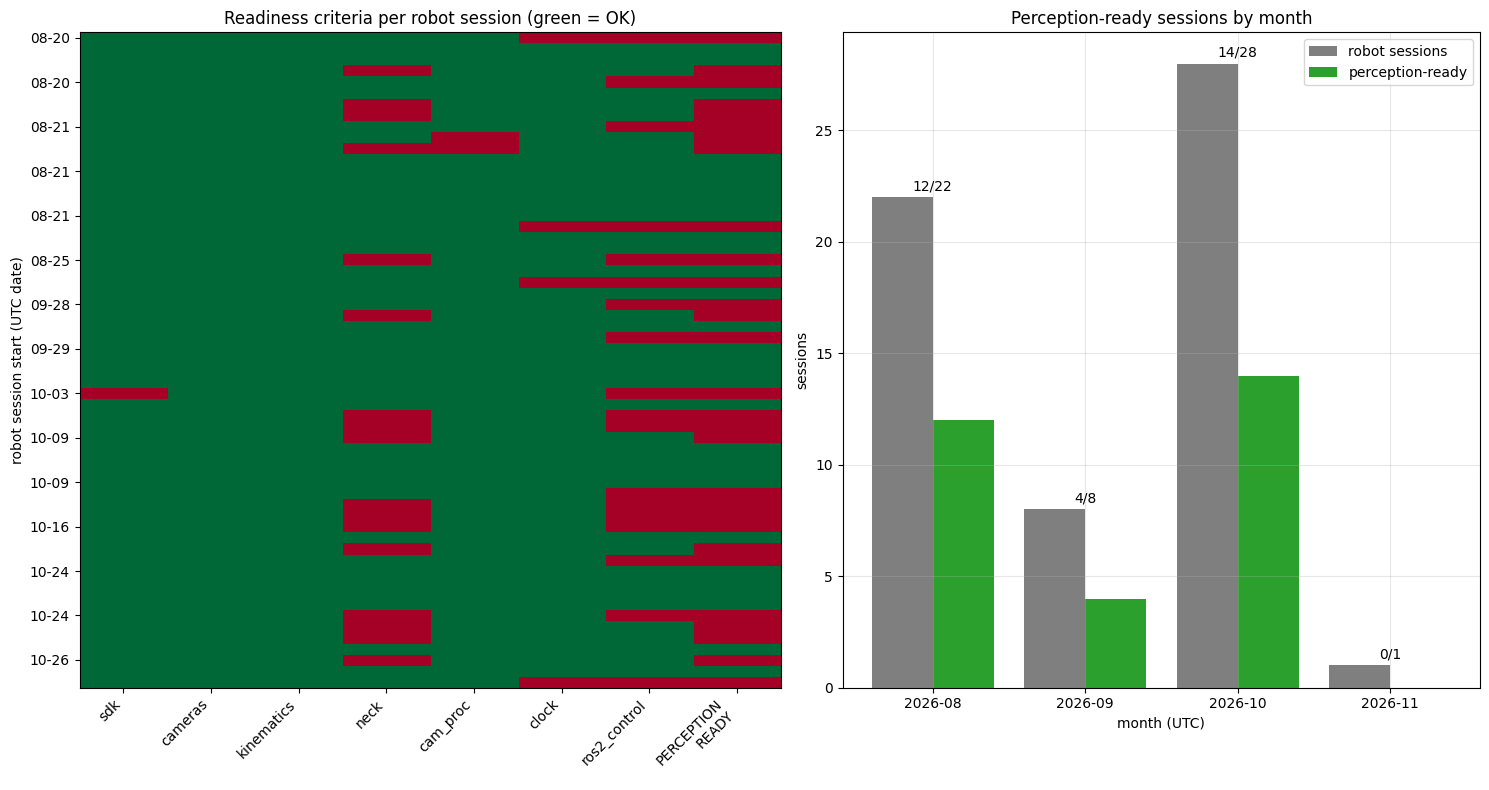

In [22]:
# @title 10. Per-session perception readiness table, strip chart and share by month
RD = R.sort_values("start_utc").copy()
RD["ok_sdk"] = RD["sdk_ready"]; RD["ok_cameras"] = RD["cameras_ready"]; RD["ok_kinematics"] = RD["kinematics_ready"]
RD["ok_neck"] = RD["neck_w"] == 0; RD["ok_cam_proc"] = ~RD["cam_death"]; RD["ok_clock"] = RD["n_clock_steps_back"] == 0; RD["ok_ros2_control"] = ~RD["cn_death"]
crit = ["ok_sdk", "ok_cameras", "ok_kinematics", "ok_neck", "ok_cam_proc", "ok_clock", "ok_ros2_control"]
RD["ready_spec"] = RD[crit[:-1]].all(axis=1)
RD["perception_ready"] = RD[crit].all(axis=1)
RD["ready_5min"] = RD["perception_ready"] & (RD["duration_s"] >= 300)
n = len(RD)
print(f"Robot sessions: {n} | ready_spec: {int(RD['ready_spec'].sum())} ({100*RD['ready_spec'].mean():.1f}%) | "
      f"perception_ready: {int(RD['perception_ready'].sum())} ({100*RD['perception_ready'].mean():.1f}%) | ready_5min: {int(RD['ready_5min'].sum())} ({100*RD['ready_5min'].mean():.1f}%)")
print(f"Uptime in perception_ready sessions: {RD.loc[RD['perception_ready'],'uptime_h'].sum():.2f} h of {RD['uptime_h'].sum():.2f} h")
fail = RD[crit].eq(False).sum().rename("sessions_failing")
print("\nFailing sessions per criterion:\n", fail.to_string())
bym = RD.groupby("month").agg(sessions=("session_id", "size"), ready=("perception_ready", "sum"), ready_5min=("ready_5min", "sum"),
                              uptime_h=("uptime_h", "sum"))
bym["share_%"] = (100 * bym["ready"] / bym["sessions"]).round(1)
bym["uptime_ready_h"] = RD[RD["perception_ready"]].groupby("month")["uptime_h"].sum().reindex(bym.index).fillna(0)
bym["uptime_ready_%"] = (100 * bym["uptime_ready_h"] / bym["uptime_h"]).round(1)
print("\nBy month:\n", bym.round(2))
tab = RD[["session_id", "duration_s", "sdk_ready", "cameras_ready", "kinematics_ready", "neck_w", "cam_death", "n_clock_steps_back", "cn_death", "perception_ready"]].copy()
tab["session_id"] = tab["session_id"].str.slice(0, 16)
print("\nReadiness table (first 20 of %d rows):" % n); print(tab.head(20).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(15, 8), gridspec_kw={"width_ratios": [1.1, 1]})
M2 = RD[crit + ["perception_ready"]].values.astype(float)
ax[0].imshow(M2, cmap="RdYlGn", vmin=0, vmax=1, aspect="auto"); ax[0].grid(False)
ax[0].set_xticks(range(len(crit) + 1)); ax[0].set_xticklabels([c.replace("ok_", "") for c in crit] + ["PERCEPTION\nREADY"], rotation=45, ha="right")
ax[0].set_yticks(range(0, n, 4)); ax[0].set_yticklabels([f"{d:%m-%d}" for d in RD["start_utc"].iloc[::4]])
ax[0].set_ylabel("robot session start (UTC date)"); ax[0].set_title("Readiness criteria per robot session (green = OK)")
x = np.arange(len(bym)); ax[1].bar(x - 0.2, bym["sessions"], 0.4, label="robot sessions", color="tab:gray"); ax[1].bar(x + 0.2, bym["ready"], 0.4, label="perception-ready", color="tab:green")
for i, (s_, r_) in enumerate(zip(bym["sessions"], bym["ready"])): ax[1].text(i, max(s_, r_) + 0.3, f"{r_}/{s_}", ha="center")
ax[1].set_xticks(x); ax[1].set_xticklabels(bym.index); ax[1].set_xlabel("month (UTC)"); ax[1].set_ylabel("sessions"); ax[1].set_title("Perception-ready sessions by month"); ax[1].legend()
plt.tight_layout(); plt.show()

## 11. Ad-hoc event filter

**What it does.** Filters `events` by session (substring of `session_id`), node, category, source, time window and free text, and prints the matching rows with UTC and local timestamps. Edit the form fields and re-run.

**How to read the output.** One row per event; `ts_local` is America/Los_Angeles. `SOURCE` = `canonical` keeps launch events plus the node-only `hw_bus_error` rows, which avoids double counting; `any` shows both sources.

**Caveat.** `hw_bus_error` rows are throttled windows (see overview). Time-window strings are UTC (`YYYY-MM-DD[ HH:MM]`); leave blank for no bound.

In [23]:
# @title 11. Filter events by session / node / category / time window
SESSION_ID = ""            # @param {type:"string"}
NODE = ""                  # @param {type:"string"}
CATEGORY = "traceback"     # @param ["any", "lifecycle", "hw_bus_error", "fan", "camera", "kinematics", "sdk_server", "controller", "mobile_base", "lidar", "traceback", "warning", "launch", "other"]
SOURCE = "canonical"       # @param ["canonical", "launch", "node", "any"]
START_UTC = ""             # @param {type:"string"}
END_UTC = ""               # @param {type:"string"}
TEXT = ""                  # @param {type:"string"}
MAX_ROWS = 40              # @param {type:"integer"}

def filter_events(ev=EV):
    m = pd.Series(True, index=ev.index)
    if SESSION_ID: m &= ev["session_id"].fillna("").str.contains(SESSION_ID, regex=False)
    if NODE: m &= ev["node"].fillna("").str.contains(NODE, regex=False)
    if CATEGORY != "any": m &= ev["category"] == CATEGORY
    if SOURCE == "canonical": m &= (ev["source_kind"] == "launch") | (ev["category"] == "hw_bus_error")
    elif SOURCE in ("launch", "node"): m &= ev["source_kind"] == SOURCE
    if START_UTC: m &= ev["ts_utc"] >= pd.Timestamp(START_UTC, tz="UTC")
    if END_UTC: m &= ev["ts_utc"] <= pd.Timestamp(END_UTC, tz="UTC")
    if TEXT: m &= ev["message"].fillna("").str.contains(TEXT, case=False, regex=False)
    return ev[m].sort_values("epoch")

F = filter_events()
print(f"{len(F):,} matching events; sessions: {F['session_id'].nunique()}; nodes: {F['node'].nunique()}")
print(F[["ts_utc", "ts_local", "session_id", "node", "level", "category", "message"]].head(MAX_ROWS)
      .assign(session_id=lambda d: d["session_id"].str.slice(0, 16), message=lambda d: d["message"].str.slice(0, 90)).to_string(index=False))

553 matching events; sessions: 15; nodes: 1
                          ts_utc                         ts_local       session_id     node level  category                                                                                    message
2026-08-20 14:44:52.552000+00:00 2026-08-20 07:44:52.552000-07:00 2026-08-20-16-44 zuuu_hal ERROR traceback                                                         Traceback (most recent call last):
2026-08-20 14:44:52.552000+00:00 2026-08-20 07:44:52.552000-07:00 2026-08-20-16-44      NaN   NaN traceback   File "/home/reachy/.local/lib/python3.10/site-packages/serial/serialposix.py", line 322,
2026-08-20 14:44:52.552000+00:00 2026-08-20 07:44:52.552000-07:00 2026-08-20-16-44      NaN   NaN traceback                   self.fd = os.open(self.portstr, os.O_RDWR | os.O_NOCTTY | os.O_NONBLOCK)
2026-08-20 14:44:52.553000+00:00 2026-08-20 07:44:52.553000-07:00 2026-08-20-16-44      NaN   NaN traceback                 FileNotFoundError: [Errno 2] No such

## 12. Boots, logged span vs possible span, and all-bus outages

Two corrections to how sections 2, 5, 6 and 10 should be read.

**"Uptime" above is a logged span, not a run time.** A session's `duration_s` ends at its last log line. No launch was ever shut down cleanly in these logs, and a healthy stack logs nothing after bringup, so a quiet healthy session looks about 20 s long. The mobile-base launch that starts at every boot prints one line per second until the computer goes off, so its span is the computer-on time for that boot. This cell assigns each robot session to a boot and gives a lower bound (logged span) and an upper bound (until the next relaunch, the controller abort, or the end of the boot).

**Most error windows belong to a few all-bus outages.** An outage here is a run of at least 15 minutes in which 5-minute bins hold 60 or more error windows and all three systems (arm, antennas, neck) are failing. The three systems sit on three separate serial adapters, so a simultaneous, saturated failure points at something they share (motor power or the emergency stop is the first thing to check) and not at one bad cable. Thresholds are the constants at the top of the cell.

In [24]:
# @title 12a. Boot assignment, logged vs possible span, and all-bus outage detection
BIN_S, SAT_MIN, MIN_BINS = 300, 60, 3   # 5-min bins; >=60 windows (of ~130 possible) and all 3 systems; >=15 min


def find_outages(hw, sessions, processes):
    died = processes[(processes.executable.str.contains("ros2_control")) & (processes.died == True)].set_index("session_id").died_epoch
    start = sessions.set_index("session_id").start_epoch
    rows = []
    for sid, x in hw.groupby("session_id"):
        b = ((x.epoch - start[sid]) // BIN_S).astype(int)
        g = x.groupby(b).agg(n=("epoch", "size"), nsys=("system", "nunique"))
        sat = sorted(g.index[(g.n >= SAT_MIN) & (g.nsys == 3)])
        run = []
        for k in sat + [None]:
            if run and (k is None or k != run[-1] + 1):
                if len(run) >= MIN_BINS:
                    t0, t1 = start[sid] + run[0] * BIN_S, start[sid] + (run[-1] + 1) * BIN_S
                    xs = x[(x.epoch >= t0) & (x.epoch < t1)]
                    d = died.get(sid, np.nan)
                    rows.append(dict(session_id=sid, onset_epoch=xs.epoch.min(), end_epoch=xs.epoch.max(),
                                     onset_utc=pd.to_datetime(xs.epoch.min(), unit="s", utc=True).isoformat(),
                                     end_utc=pd.to_datetime(xs.epoch.max(), unit="s", utc=True).isoformat(),
                                     onset_h_into_session=(xs.epoch.min() - start[sid]) / 3600,
                                     duration_h=(xs.epoch.max() - xs.epoch.min()) / 3600, n_error_windows=len(xs),
                                     windows_per_h=len(xs) / max((xs.epoch.max() - xs.epoch.min()) / 3600, 1e-9),
                                     ended_by="ros2_control_node abort" if (d == d and d - xs.epoch.max() < 600) else "recovered or log ended",
                                     s_last_window_to_abort=(d - xs.epoch.max()) if d == d else np.nan))
                run = []
            if k is not None:
                run.append(k)
    return pd.DataFrame(rows).sort_values("onset_epoch").reset_index(drop=True)


def robot_sessions(sessions, processes, outages):
    s = sessions.sort_values("start_epoch")
    m = s[s.launch_type == "mobile_base"].reset_index(drop=True)
    r = s[s.launch_type == "robot_bringup"].copy()
    r["boot_id"] = [(m.start_epoch <= t + 90).sum() - 1 for t in r.start_epoch]
    r["boot_end_epoch"] = r.boot_id.map(m.end_epoch)
    r["boot_uptime_h"] = r.boot_id.map(m.duration_s) / 3600
    nxt = r.start_epoch.shift(-1)
    died = processes[(processes.executable.str.contains("ros2_control")) & (processes.died == True)].set_index("session_id").died_epoch
    r["ros2_control_died"] = r.session_id.isin(died.index)
    upper = pd.concat([r.boot_end_epoch, nxt], axis=1).min(axis=1)
    r["logged_span_h"] = r.duration_s / 3600
    r["possible_span_h"] = np.where(r.ros2_control_died, r.logged_span_h, np.maximum((upper - r.start_epoch) / 3600, r.logged_span_h))
    o = outages.groupby("session_id").agg(outage_h=("duration_h", "sum"), outage_windows=("n_error_windows", "sum"))
    r = r.merge(o, left_on="session_id", right_index=True, how="left").fillna({"outage_h": 0, "outage_windows": 0})
    r["non_outage_error_windows"] = r.n_hw_error_rows - r.outage_windows
    keep = ["session_id", "start_utc", "boot_id", "boot_uptime_h", "logged_span_h", "possible_span_h", "ros2_control_died",
            "sdk_ready", "n_hw_error_rows", "outage_h", "outage_windows", "non_outage_error_windows", "n_fan_on_events", "n_clock_steps_back"]
    return r[keep], m

OUT = find_outages(T["hw_errors"].assign(epoch=T["hw_errors"]["epoch"]), T["sessions"], T["processes"])
RS, BOOTS = robot_sessions(T["sessions"], T["processes"], OUT)
n_all, n_out = len(T["hw_errors"]), int(OUT.n_error_windows.sum())
print(f"boots: {len(BOOTS)} | computer-on {BOOTS.duration_s.sum()/3600:.0f} h | robot stack logged {RS.logged_span_h.sum():.1f} h (lower bound) | possible {RS.possible_span_h.sum():.1f} h (upper bound)")
print(f"all-bus outages: {len(OUT)} | {OUT.duration_h.sum():.1f} h | {n_out:,} of {n_all:,} error windows ({100*n_out/n_all:.1f} %)")
display(OUT[["session_id","onset_utc","onset_h_into_session","duration_h","n_error_windows","windows_per_h","ended_by","s_last_window_to_abort"]].round(2))
display(RS.round(2))


boots: 13 | computer-on 700 h | robot stack logged 95.2 h (lower bound) | possible 199.7 h (upper bound)
all-bus outages: 7 | 41.3 h | 60,393 of 67,236 error windows (89.8 %)


,session_id,onset_utc,onset_h_into_session,duration_h,n_error_windows,windows_per_h,ended_by,s_last_window_to_abort
0,2026-08-25-21-16-24-980200-reachy-2023-R0027-724377,2026-08-25T20:41:25.055804968+00:00,1.42,1.07,1547,1439.28,ros2_control_node abort,117.80
1,2026-10-03-19-58-35-792689-reachy-2023-R0027-505700,2026-10-03T18:34:08.788990974+00:00,0.59,0.82,1168,1418.08,ros2_control_node abort,246.69
2,2026-10-06-22-36-28-980717-reachy-2023-R0027-2034445,2026-10-06T21:11:33.857048035+00:00,0.58,8.04,11549,1436.08,ros2_control_node abort,73.97
3,2026-10-09-21-58-44-548859-reachy-2023-R0027-2048,2026-10-09T20:28:49.416191101+00:00,0.50,0.25,360,1462.23,ros2_control_node abort,134.43
4,2026-10-13-21-28-11-876815-reachy-2023-R0027-58694,2026-10-13T20:03:28.993968964+00:00,0.59,9.08,14124,1556.30,ros2_control_node abort,128.29
5,2026-10-16-20-15-00-752231-reachy-2023-R0027-1087949,2026-10-16T19:55:00.894299984+00:00,1.67,14.30,20552,1437.28,ros2_control_node abort,89.59
6,2026-10-24-19-32-52-780765-reachy-2023-R0027-212432,2026-10-24T18:45:08.053375006+00:00,1.20,7.71,11093,1438.53,ros2_control_node abort,43.65


,session_id,start_utc,boot_id,boot_uptime_h,logged_span_h,possible_span_h,ros2_control_died,sdk_ready,n_hw_error_rows,outage_h,outage_windows,non_outage_error_windows,n_fan_on_events,n_clock_steps_back
0,2026-08-20-16-44-45-356478-reachy-2023-R0027-1918,2026-08-20 14:44:45.359000+00:00,0,3.70,0.01,0.01,True,True,0,0.00,0.0,0.0,0,1
2,2026-08-20-16-52-51-306516-reachy-2023-R0027-25799,2026-08-20 14:52:51.341000+00:00,0,3.70,0.01,0.46,False,True,84,0.00,0.0,84.0,0,0
3,2026-08-20-17-20-13-908555-reachy-2023-R0027-88156,2026-08-20 15:20:13.909000+00:00,0,3.70,0.01,0.09,False,True,1,0.00,0.0,1.0,0,0
4,2026-08-20-17-25-47-077902-reachy-2023-R0027-100618,2026-08-20 15:25:47.078000+00:00,0,3.70,2.19,3.02,False,True,1063,0.00,0.0,1063.0,4,0
5,2026-08-20-21-19-27-588262-reachy-2023-R0027-2167,2026-08-20 19:19:27.590000+00:00,1,0.40,0.01,0.01,True,True,1,0.00,0.0,1.0,0,0
7,2026-08-20-21-22-02-477916-reachy-2023-R0027-12128,2026-08-20 19:22:02.512000+00:00,1,0.40,0.01,0.02,False,True,1,0.00,0.0,1.0,0,0
8,2026-08-20-21-23-24-213243-reachy-2023-R0027-15190,2026-08-20 19:23:24.213000+00:00,1,0.40,0.01,0.33,False,True,80,0.00,0.0,80.0,0,0
9,2026-08-20-21-48-30-598756-reachy-2023-R0027-2169,2026-08-20 19:48:30.600000+00:00,2,1.27,0.01,1.28,False,True,193,0.00,0.0,193.0,0,0
11,2026-08-21-15-57-01-796459-reachy-2023-R0027-2023,2026-08-21 13:57:01.798000+00:00,3,4.27,0.01,0.01,True,True,0,0.00,0.0,0.0,0,0
13,2026-08-21-20-05-23-998765-reachy-2023-R0027-247942,2026-08-21 18:05:24.033000+00:00,3,4.27,0.01,0.01,False,True,1,0.00,0.0,1.0,0,0


### 12b. Anatomy of the longest outage, and what is left outside outages

Left: error windows per 5 minutes by system for the longest outage, with fan events (grey) and the controller abort (red). Fan events stop when the outage starts because the fan controller can no longer read temperatures. Right: error windows outside outages by system and signal. These residual windows are the ones that describe the bus in normal operation.

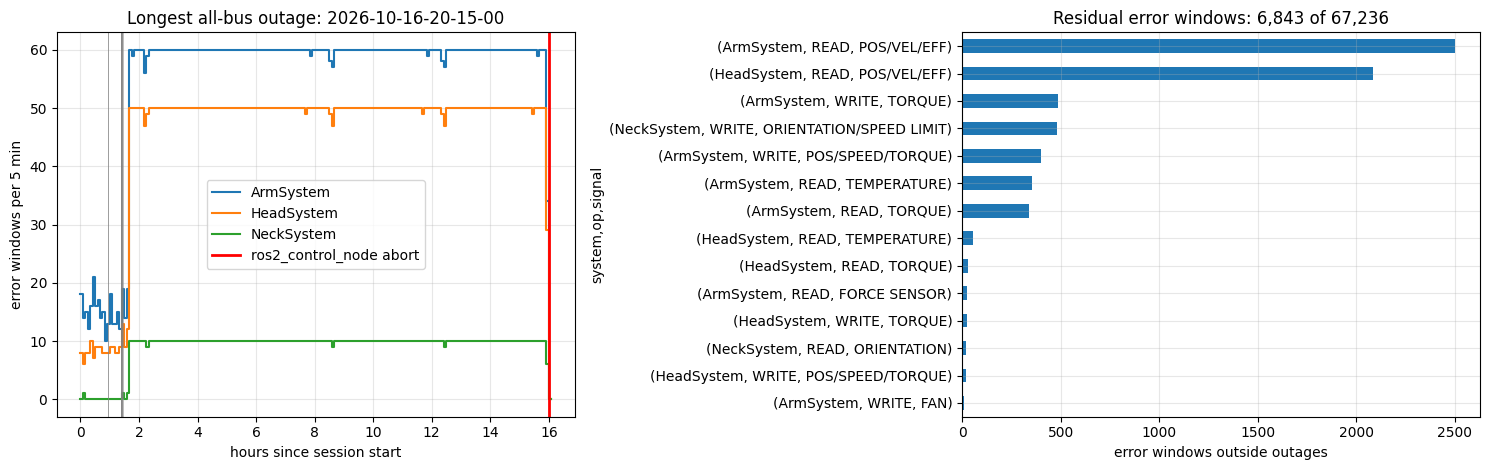

residual NeckSystem windows: {('READ', 'ORIENTATION'): 20, ('WRITE', 'ORIENTATION/SPEED LIMIT'): 483} | sessions: 16
residual windows per logged non-outage hour: 127.0


In [25]:
# @title 12b. Outage anatomy and residual (non-outage) error windows by system and signal
hw = T["hw_errors"]; sid = OUT.sort_values("duration_h").session_id.iloc[-1]
st = T["sessions"].set_index("session_id").start_epoch[sid]; x = hw[hw.session_id == sid]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
bins = np.arange(0, (x.epoch.max() - st) / 3600 + 0.25, 1 / 12)
for name in ("ArmSystem", "HeadSystem", "NeckSystem"):
    v, _ = np.histogram((x[x.system == name].epoch - st) / 3600, bins=bins)
    axes[0].step(bins[:-1], v, where="post", label=name)
for t in (T["fan_events"][T["fan_events"].session_id == sid].epoch - st) / 3600:
    axes[0].axvline(t, color="grey", lw=0.6, alpha=0.6)
dd = T["processes"]; dd = dd[(dd.session_id == sid) & dd.executable.str.contains("ros2_control") & (dd.died == True)].died_epoch
if len(dd): axes[0].axvline((dd.iloc[0] - st) / 3600, color="red", lw=2, label="ros2_control_node abort")
axes[0].set_xlabel("hours since session start"); axes[0].set_ylabel("error windows per 5 min"); axes[0].set_title(f"Longest all-bus outage: {sid[:19]}"); axes[0].legend(); axes[0].grid(alpha=0.3)
res = hw.merge(OUT[["session_id", "onset_epoch", "end_epoch"]], on="session_id", how="left")
res = res[~((res.epoch >= res.onset_epoch) & (res.epoch <= res.end_epoch))]
RES = res.drop_duplicates(["session_id", "epoch", "system", "signal", "op"])
tab = RES.groupby(["system", "op", "signal"]).size().sort_values()
tab.plot.barh(ax=axes[1]); axes[1].set_xlabel("error windows outside outages"); axes[1].set_title(f"Residual error windows: {len(RES):,} of {len(hw):,}"); axes[1].grid(alpha=0.3, axis="x")
plt.tight_layout(); plt.show()
neck = RES[RES.system == "NeckSystem"]
print("residual NeckSystem windows:", neck.groupby(["op", "signal"]).size().to_dict(), "| sessions:", neck.session_id.nunique())
print("residual windows per logged non-outage hour:", round(len(RES) / (RS.logged_span_h.sum() - OUT.duration_h.sum()), 1))


## Findings to investigate / next steps

*(Written from the outputs of this run on data to 2026-11-12; re-check the numbers after re-running on new logs. Section 12 changes how several earlier sections should be read, and this list reflects that.)*

**What the data show**
- **Log volume is about 99 % spam.** 5.03 M of 5.12 M lines (98.3 %) are `SetSpeed not available` from the mobile-base launch that starts at every boot on a robot with no mobile base; 660 of 1,426 files (46 %) are empty.
- **Session "uptime" is a logged span.** 36 of 59 robot sessions show under 60 s of log, but that only means nothing was logged after bringup. The computer was on for about 700 h over 13 boots; the robot stack was up for between 95 h (logged) and about 200 h (upper bound).
- **Bringup is fast and stable.** SDK ready median 12.7 s, p95 14.6 s; cameras ready median 5.9 s; no trend. One robot session (2026-10-03) never reached SDK ready.
- **About 90 % of bus-error windows come from 7 all-bus outages** (41 h in total). Arm, antenna and neck buses fail in the same minute, stay saturated, fan events stop, and `ros2_control_node` aborts (exit -6) 44 to 247 s after the last window. All 7 end in an abort. The first thing to check is motor power or the emergency stop being off while the computer stays on.
- **`ros2_control_node` aborts fall into two groups:** the 7 outage aborts above, and about 9 aborts within 20 s of the boot-time autostart launch (the operator then relaunches by hand). These need separate explanations.
- **Outside outages the bus is mostly quiet for perception purposes.** About 6,800 residual windows, mainly `READ POS/VEL/EFF` on the arm and antenna buses. The neck shows about 500, almost all `WRITE ORIENTATION/SPEED LIMIT`; neck orientation reads (head pose) fail in about 20 windows.
- **Thermal:** the wrist fan flaps (ON for about 1 s) in 18 sessions, worst on 2026-10-26; the elbow fan stays on for long stretches (up to about 95 % of a session).
- **Clock:** 4 robot sessions, all the first launch after a boot, show backward steps of 1.7 to 64 s.
- **Warnings in every robot session:** NumPy/SciPy version mismatch in the SDK server and kinematics node; `Unknown tag "ros2_control"` from KDL.

**To investigate / do next**
1. Confirm the outage cause on the robot: note when motor power or the emergency stop is switched, and compare with `derived_bus_outages.csv`.
2. Capture the reason for the boot-time abort (stderr of `ros2_control_node`, `journalctl`, core dump); the logs hold no message before it.
3. Disable the mobile-base launch on this robot, or at least its autostart.
4. Wait for time sync before the autostart launch, and record clock offset in every capture.
5. Add per-frame camera timing and numeric temperatures to telemetry; these logs cannot show either.
6. Use section 10 together with section 12 as a pre-capture check: stack up, no outage in progress, no clock step.
